# Predicting Age from Xray Images using a Publicly Available Dataset
Disclosure: Copilot was used to help code and debug these models
## Dataset Download and Inspection
Download the sample dataset and inspect its images and metadata before preparing model inputs.

### Setting up the Data

First lets import our data and do some basic checks.

In [37]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nih-chest-xrays/sample")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Felix\.cache\kagglehub\datasets\nih-chest-xrays\sample\versions\4


Loading first image: C:\Users\Felix\.cache\kagglehub\datasets\nih-chest-xrays\sample\versions\4\sample\images\00000013_005.png


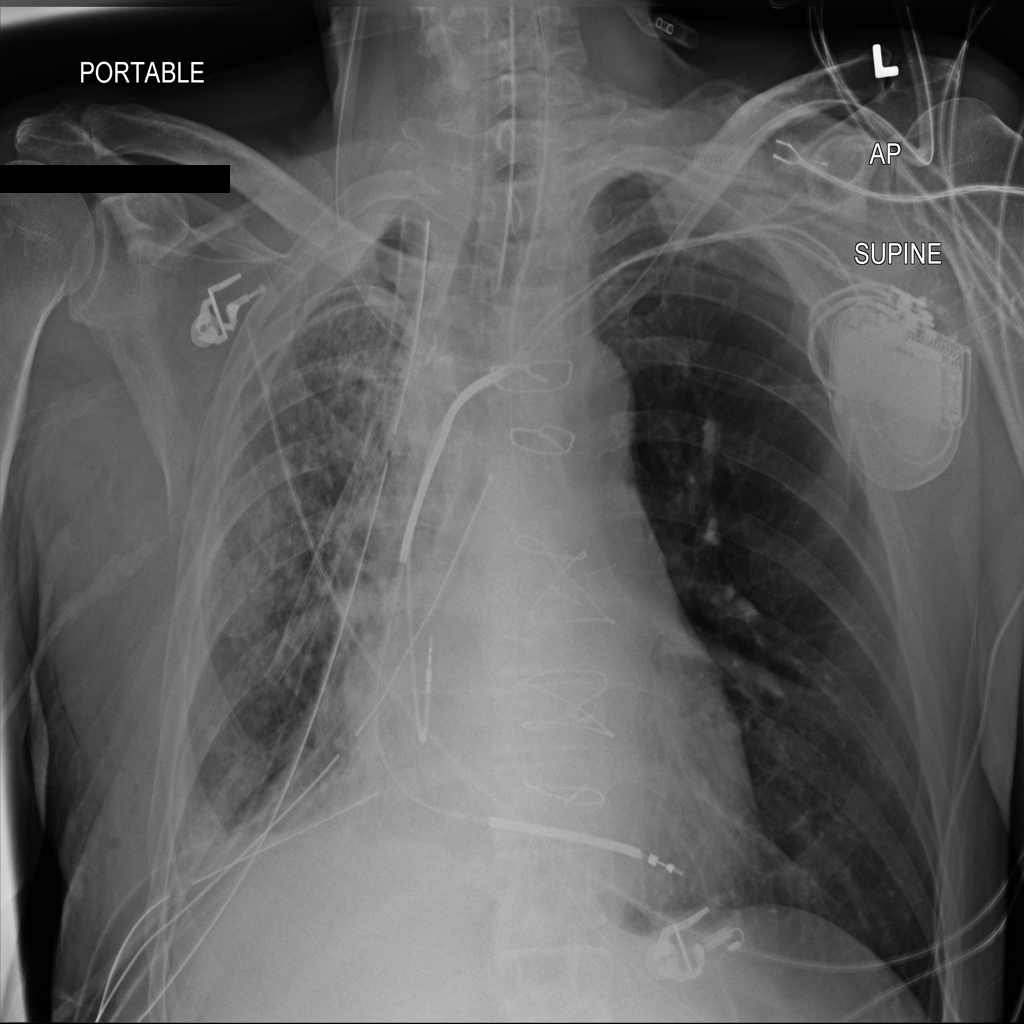

In [38]:
import os
from PIL import Image

# List contents of the downloaded dataset directory
# Assuming the images are directly under the 'sample' directory or a subdirectory within it.
# Let's try to find a common image extension like .png or .jpg

image_files = []
for root, _, files in os.walk(path):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            image_files.append(os.path.join(root, file))

if image_files:
    # Sort the files to ensure consistent 'first' image if there are many
    image_files.sort()
    first_image_path = image_files[0]
    print(f"Loading first image: {first_image_path}")

    # Open and display the image
    img = Image.open(first_image_path)
    display(img)
else:
    print("No image files (png, jpg, jpeg) found in the dataset directory.")

In [39]:
print(f"Total image files found: {len(image_files)}")

Total image files found: 11212


### Taking a look at the distribution of age in the sample
Using the metadata file sample_labels.csv, I took a look at the distribution of age in this dataset.

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

metadata_file_path = os.path.join(path, "sample", "sample_labels.csv")

if os.path.exists(metadata_file_path):
    print(f"Loading metadata from: {metadata_file_path}")
    df_metadata = pd.read_csv(metadata_file_path)

    # Convert ages such as "060Y" to numbers, then exclude age 411.
    age_numeric = pd.to_numeric(
        df_metadata["Patient Age"].astype(str).str.replace("Y", "", regex=False),
        errors="coerce"
    )

    excluded_images = df_metadata.loc[age_numeric == 411, "Image Index"].tolist()
    df_metadata = df_metadata.loc[age_numeric != 411].copy()

    print("Excluded image(s):", excluded_images)
    display(df_metadata.head())
else:
    print(f"Metadata file not found at: {metadata_file_path}")

# Show the age range after excluding the age-411 row(s).
ages = pd.to_numeric(
    df_metadata["Patient Age"].astype(str).str.replace("Y", "", regex=False),
    errors="coerce"
).dropna()

print(f"Age range: {ages.min():.0f} to {ages.max():.0f} years")


Loading metadata from: C:\Users\Felix\.cache\kagglehub\datasets\nih-chest-xrays\sample\versions\4\sample\sample_labels.csv
Excluded image(s): ['00020900_002.png']


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImageWidth,OriginalImageHeight,OriginalImagePixelSpacing_x,OriginalImagePixelSpacing_y
0,00000013_005.png,Emphysema|Infiltration|Pleural_Thickening|Pneu...,5,13,060Y,M,AP,3056,2544,0.139,0.139
1,00000013_026.png,Cardiomegaly|Emphysema,26,13,057Y,M,AP,2500,2048,0.168,0.168
2,00000017_001.png,No Finding,1,17,077Y,M,AP,2500,2048,0.168,0.168
3,00000030_001.png,Atelectasis,1,30,079Y,M,PA,2992,2991,0.143,0.143
4,00000032_001.png,Cardiomegaly|Edema|Effusion,1,32,055Y,F,AP,2500,2048,0.168,0.168


Age range: 2 to 94 years


I previously checked the actual csv data file to check for any missing data. I noticed instead that while there were no missing age labels, there was an outlier of 411 years old. This was most likely a typo for 41, but I decided to simply remove the row for this project.

## Data Cleaning and Patient-Level Splits
Building the datasets and loaders, and split patients into training, validation, and test sets.

In [41]:

from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

# The variable `path` was set in an earlier cell to the Kaggle dataset folder.
DATA_DIR = Path(path)
METADATA_FILE = DATA_DIR / "sample" / "sample_labels.csv"
IMAGE_DIR = DATA_DIR / "sample"

# Load the image labels and metadata from the CSV.
df_metadata = pd.read_csv(METADATA_FILE)

# Exclude the age-411 row(s) before building the datasets.
age_numeric = pd.to_numeric(
    df_metadata["Patient Age"].astype(str).str.replace("Y", "", regex=False),
    errors="coerce"
)
excluded_images = df_metadata.loc[age_numeric == 411, "Image Index"].tolist()
df_metadata = df_metadata.loc[age_numeric != 411].copy()

# Convert remaining ages to integers and discard invalid/missing ages.
df_metadata["Age"] = pd.to_numeric(
    df_metadata["Patient Age"].astype(str).str.replace("Y", "", regex=False),
    errors="coerce"
)
df_metadata = df_metadata.dropna(subset=["Age"]).copy()
df_metadata["Age"] = df_metadata["Age"].astype(int)

# Create one class ID for each distinct age.
classes = sorted(df_metadata["Age"].unique())
age_to_class = {age: class_id for class_id, age in enumerate(classes)}
df_metadata["Age Class"] = df_metadata["Age"].map(age_to_class).astype(int)

# Find image files under the sample folder and match them to the CSV filenames.
image_paths = {
    image_file.name: image_file
    for image_file in IMAGE_DIR.rglob("*")
    if image_file.is_file() and image_file.suffix.lower() in {".png", ".jpg", ".jpeg"}
}

missing_images = [
    filename for filename in df_metadata["Image Index"]
    if filename not in image_paths
]
if missing_images:
    raise FileNotFoundError(
        f"Could not find {len(missing_images)} images. "
        f"Examples: {missing_images[:5]}"
    )

# Resize the images, convert them to tensors, and normalize pixel values to [-1, 1].
# Use light augmentation only on the training split to improve generalization.
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.9, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

class ChestXrayDataset(Dataset):
    def __init__(self, metadata, transform=None, sex_column=None):
        self.metadata = metadata.reset_index(drop=True)
        self.transform = transform

        sex_candidates = ["Patient Gender", "Sex", "Gender"]
        self.sex_column = sex_column or next(
            (col for col in sex_candidates if col in self.metadata.columns),
            None,
        )
        self.sex_map = {"F": 0.0, "M": 1.0, "0": 0.0, "1": 1.0}

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, index):
        row = self.metadata.iloc[index]
        image_path = image_paths[row["Image Index"]]

        image = Image.open(image_path).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)

        if self.sex_column is None:
            sex = torch.tensor(0.0, dtype=torch.float32)
        else:
            sex_value = str(row[self.sex_column]).strip().upper()
            sex = torch.tensor(self.sex_map.get(sex_value, 0.0), dtype=torch.float32)

        age = torch.tensor(float(row["Age"]), dtype=torch.float32)
        return image, sex, age

# Split by patient so images from the same patient stay in only one dataset.
patient_ids = df_metadata["Patient ID"].drop_duplicates().to_numpy().copy()

if len(patient_ids) < 3:
    raise ValueError("At least three different patients are needed for train, validation, and test sets.")

rng = np.random.default_rng(42)
rng.shuffle(patient_ids)

# Assign approximately 15% of patients to test and 15% to validation.
test_patient_count = max(1, round(len(patient_ids) * 0.15))
validation_patient_count = max(1, round(len(patient_ids) * 0.15))

test_patient_ids = patient_ids[:test_patient_count]
validation_patient_ids = patient_ids[
    test_patient_count:test_patient_count + validation_patient_count
]
train_patient_ids = patient_ids[
    test_patient_count + validation_patient_count:
]

train_metadata = df_metadata[df_metadata["Patient ID"].isin(train_patient_ids)].copy()
validation_metadata = df_metadata[df_metadata["Patient ID"].isin(validation_patient_ids)].copy()
test_metadata = df_metadata[df_metadata["Patient ID"].isin(test_patient_ids)].copy()

# Standardize age using training rows only.
age_mean = train_metadata["Age"].mean()
age_std = train_metadata["Age"].std(ddof=0)

trainset = ChestXrayDataset(train_metadata, transform=train_transform)
validationset = ChestXrayDataset(validation_metadata, transform=val_transform)
testset = ChestXrayDataset(test_metadata, transform=val_transform)

trainloader = DataLoader(trainset, batch_size=4, shuffle=True, num_workers=0)
validationloader = DataLoader(validationset, batch_size=4, shuffle=False, num_workers=0)
testloader = DataLoader(testset, batch_size=4, shuffle=False, num_workers=0)

print("Datasets loaded successfully!")
print("Training images:", len(trainset))
print("Validation images:", len(validationset))
print("Test images:", len(testset))
print("Age mean (train):", age_mean)
print("Age std (train):", age_std)

Datasets loaded successfully!
Training images: 3929
Validation images: 843
Test images: 831
Age mean (train): 46.81649274624586
Age std (train): 16.45016608371285


## Model 1: CNN for Age Classification
Build age-class labels from the prepared splits, then train and evaluate the image classifier.

In [42]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define the Convolutional Neural Network
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        # First convolutional layer: 3 input channels (for RGB images), 6 output channels, 5x5 kernel
        self.conv1 = nn.Conv2d(3, 6, 5)
        # Max pooling layer with 2x2 window and stride 2
        self.pool = nn.MaxPool2d(2, 2)
        # Second convolutional layer: 6 input channels, 16 output channels, 5x5 kernel
        self.conv2 = nn.Conv2d(6, 16, 5)

        # Reduce the feature map size before flattening so the first dense layer stays small.
        # With a 224x224 input, two 2x2 max-pool layers reduce the spatial size a lot.
        # AdaptiveAvgPool2d((4, 4)) makes the input to fc1 16 * 4 * 4 = 256 features,
        # which cuts the dense layer from about 5.4M weights to about 31K.
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, len(classes))  # Number of output classes based on unique ages

    def forward(self, x):
        # Apply first convolution, then ReLU, then max pooling
        x = self.pool(F.relu(self.conv1(x)))
        # Apply second convolution, then ReLU, then max pooling
        x = self.pool(F.relu(self.conv2(x)))
        x = self.adaptive_pool(x)
        # Flatten the image for the fully connected layers
        x = torch.flatten(x, 1)
        # Apply fully connected layers with ReLU activation for hidden layers
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

class AgeClassDataset(Dataset):
    def __init__(self, base_dataset, metadata):
        self.base_dataset = base_dataset
        self.labels = metadata.reset_index(drop=True)["Age Class"].to_numpy(dtype="int64")

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        image, _, _ = self.base_dataset[index]
        label = torch.tensor(self.labels[index], dtype=torch.long)
        return image, label

class_trainset = AgeClassDataset(trainset, train_metadata)
class_train_eval_base = ChestXrayDataset(train_metadata, transform=val_transform)
class_train_evalset = AgeClassDataset(class_train_eval_base, train_metadata)
class_validationset = AgeClassDataset(validationset, validation_metadata)
class_testset = AgeClassDataset(testset, test_metadata)
class_trainloader = DataLoader(class_trainset, batch_size=32, shuffle=True, num_workers=0, pin_memory=device.type == "cuda")
class_train_eval_loader = DataLoader(class_train_evalset, batch_size=32, shuffle=False, num_workers=0, pin_memory=device.type == "cuda")
class_validationloader = DataLoader(class_validationset, batch_size=32, shuffle=False, num_workers=0, pin_memory=device.type == "cuda")
class_testloader = DataLoader(class_testset, batch_size=32, shuffle=False, num_workers=0, pin_memory=device.type == "cuda")

# Instantiate the network
classifier_model = Net()

classifier_model.to(device)
print("CNN model defined successfully:")
print(classifier_model)

Using device: cuda
CNN model defined successfully:
Net(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (fc1): Linear(in_features=256, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=89, bias=True)
)


In [43]:
import torch
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classifier_model = classifier_model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(classifier_model.parameters(), lr=0.001, momentum=0.9)

print("Loss function and optimizer defined.")

Loss function and optimizer defined.


In [44]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classifier_model = classifier_model.to(device)
class_age_values = torch.tensor(classes, dtype=torch.float32, device=device)
train_losses = []
train_maes = []
val_losses = []
val_maes = []
num_epochs = 20
model1_best_val_mae = float("inf")
model1_best_state = None

for epoch in range(num_epochs):
    classifier_model.train()
    running_loss = 0.0
    train_count = 0

    for inputs, labels in class_trainloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = classifier_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        train_count += labels.size(0)

    avg_train_loss = running_loss / train_count
    train_losses.append(avg_train_loss)

    # Evaluate in eval mode on the non-augmented training set and validation set.
    classifier_model.eval()
    train_eval_abs_error = 0.0
    train_eval_count = 0
    with torch.no_grad():
        for inputs_train_eval, labels_train_eval in class_train_eval_loader:
            inputs_train_eval = inputs_train_eval.to(device)
            labels_train_eval = labels_train_eval.to(device)
            outputs_train_eval = classifier_model(inputs_train_eval)
            predicted_ages_train_eval = class_age_values[outputs_train_eval.argmax(dim=1)]
            train_eval_abs_error += (
                predicted_ages_train_eval - class_age_values[labels_train_eval]
            ).abs().sum().item()
            train_eval_count += labels_train_eval.size(0)

    avg_train_mae = train_eval_abs_error / train_eval_count
    train_maes.append(avg_train_mae)

    val_running_loss = 0.0
    val_abs_error = 0.0
    val_count = 0

    with torch.no_grad():
        for inputs_val, labels_val in class_validationloader:
            inputs_val = inputs_val.to(device)
            labels_val = labels_val.to(device)

            outputs_val = classifier_model(inputs_val)
            loss_val = criterion(outputs_val, labels_val)
            predicted_ages_val = class_age_values[outputs_val.argmax(dim=1)]
            val_running_loss += loss_val.item() * labels_val.size(0)
            val_abs_error += (predicted_ages_val - class_age_values[labels_val]).abs().sum().item()
            val_count += labels_val.size(0)

    avg_val_ce = val_running_loss / val_count
    avg_val_mae = val_abs_error / val_count
    avg_val_loss = avg_val_mae
    val_losses.append(avg_val_loss)
    val_maes.append(avg_val_mae)

    if avg_val_mae < model1_best_val_mae:
        model1_best_val_mae = avg_val_mae
        model1_best_state = {
            key: value.detach().cpu().clone()
            for key, value in classifier_model.state_dict().items()
        }

    print(
        f"Epoch {epoch + 1:02d}/{num_epochs} | "
        f"train_mae={avg_train_mae:.3f} years | "
        f"val_loss={avg_val_loss:.3f} years | val_mae={avg_val_mae:.3f} years | "
        f"train_ce={avg_train_loss:.4f} | val_ce={avg_val_ce:.4f}"
    )

if model1_best_state is not None:
    classifier_model.load_state_dict(model1_best_state)

print("Finished Training")

Epoch 01/20 | train_mae=26.667 years | val_loss=26.339 years | val_mae=26.339 years | train_ce=4.4976 | val_ce=4.4872
Epoch 02/20 | train_mae=18.128 years | val_loss=19.171 years | val_mae=19.171 years | train_ce=4.4863 | val_ce=4.4778
Epoch 03/20 | train_mae=15.302 years | val_loss=15.308 years | val_mae=15.308 years | train_ce=4.4753 | val_ce=4.4686
Epoch 04/20 | train_mae=15.302 years | val_loss=15.308 years | val_mae=15.308 years | train_ce=4.4643 | val_ce=4.4594
Epoch 05/20 | train_mae=15.302 years | val_loss=15.308 years | val_mae=15.308 years | train_ce=4.4530 | val_ce=4.4500
Epoch 06/20 | train_mae=15.302 years | val_loss=15.308 years | val_mae=15.308 years | train_ce=4.4413 | val_ce=4.4399
Epoch 07/20 | train_mae=15.302 years | val_loss=15.308 years | val_mae=15.308 years | train_ce=4.4286 | val_ce=4.4290
Epoch 08/20 | train_mae=15.299 years | val_loss=15.306 years | val_mae=15.306 years | train_ce=4.4139 | val_ce=4.4157
Epoch 09/20 | train_mae=15.163 years | val_loss=15.185 y

In [45]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classifier_model = classifier_model.to(device)
class_age_values = torch.tensor(classes, dtype=torch.float32, device=device)
classifier_model.eval()

test_running_loss = 0.0
test_abs_error = 0.0
test_baseline_abs_error = 0.0
baseline_age = float(train_metadata["Age"].median())
correct = 0
total = 0

with torch.no_grad():
    for inputs, labels in class_testloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = classifier_model(inputs)
        loss = criterion(outputs, labels)
        test_running_loss += loss.item() * labels.size(0)

        # The predicted class is the one with the largest output score.
        predicted = outputs.argmax(dim=1)
        predicted_ages = class_age_values[predicted]
        test_abs_error += (predicted_ages - class_age_values[labels]).abs().sum().item()
        test_baseline_abs_error += (class_age_values[labels] - baseline_age).abs().sum().item()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_ce = test_running_loss / total
test_mae = test_abs_error / total
baseline_mae = test_baseline_abs_error / total
avg_test_loss = test_mae
test_accuracy = 100 * correct / total

print(f"Test Loss (MAE): {avg_test_loss:.3f} years | Test MAE: {test_mae:.3f} years")
print(f"Baseline MAE: {baseline_mae:.3f} years")
print(f"Test CE: {test_ce:.4f} | Test Accuracy: {test_accuracy:.2f}% ({correct}/{total})")

Test Loss (MAE): 15.657 years | Test MAE: 15.657 years
Baseline MAE: 14.789 years
Test CE: 4.2976 | Test Accuracy: 1.32% (11/831)


The model architecture is very simple and we are training the model from scratch, so it is expected that the model is this bad. Outside of a simple model architecture, there could also be some structural issues to the dataset that is limiting this version of the neural network. I also learned how we need to have positives for each classification if we are going to use our neural network to try to identify each different class.

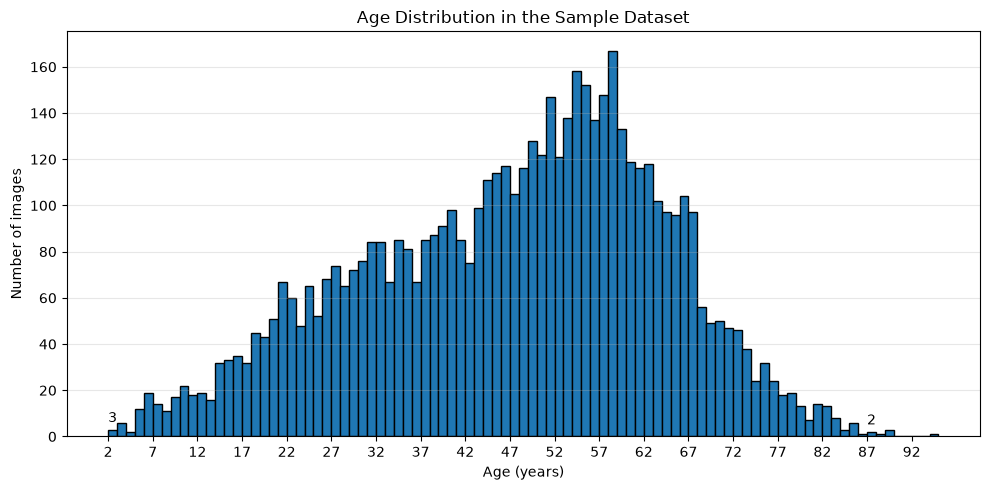

In [46]:
plt.figure(figsize=(10, 5))
age_counts, age_bin_edges, age_bars = plt.hist(
    ages,
    bins=range(int(ages.min()), int(ages.max()) + 2),
    edgecolor="black"
)

# Label the bars for ages 2 and 82 with their image counts.
for age in (2, 87):
    bin_index = age - int(ages.min())
    if 0 <= bin_index < len(age_counts):
        bar = age_bars[bin_index]
        plt.annotate(
            f"{int(age_counts[bin_index])}",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom"
        )
plt.title("Age Distribution in the Sample Dataset")
plt.xlabel("Age (years)")
plt.ylabel("Number of images")
plt.xticks(range(int(ages.min()), int(ages.max()) + 1, 5))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


As we can see in this histogram, the data does not have many positive hits for many of the age labels. For example, there are only 2 images for the age 87 label and 3 for the age 2 label. This virtually makes it impossible for our model to properly learn how to identify an 87 year old or 2 year old from an x-ray image because we aren't showing it what that image looks like. To help solve this, I am going to change this network to regress instead of identify by classification and also add sex as a variable because I know sex has impacts on bone structure.

## Shared Age-Regression Model Definition
Adding sex labels to the dataset and adding it as a variable to our continuous-age regression CNN.

In [47]:
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from PIL import Image
from pathlib import Path

class XrayDataset(Dataset):
    def __init__(self, metadata, image_dir, transform=None, sex_column=None):
        self.metadata = metadata.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform

        sex_candidates = ["Patient Gender", "Sex", "Gender"]
        self.sex_column = sex_column or next(
            (col for col in sex_candidates if col in self.metadata.columns),
            None,
        )
        self.sex_map = {"F": 0.0, "M": 1.0, "0": 0.0, "1": 1.0}

        self.image_lookup = {
            image_file.name: image_file
            for image_file in self.image_dir.rglob("*")
            if image_file.is_file() and image_file.suffix.lower() in {".png", ".jpg", ".jpeg"}
        }

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, idx):
        row = self.metadata.iloc[idx]
        image_name = str(row["Image Index"])
        image_path = self.image_lookup.get(image_name)

        if image_path is None:
            raise FileNotFoundError(f"Could not find image '{image_name}' in {self.image_dir}")

        image = Image.open(image_path).convert("RGB")
        if self.transform:
            image = self.transform(image)

        if self.sex_column is None:
            sex = torch.tensor(0.0, dtype=torch.float32)
        else:
            sex_value = str(row[self.sex_column]).strip().upper()
            sex = torch.tensor(self.sex_map.get(sex_value, 0.0), dtype=torch.float32)

        age = torch.tensor(float(row["Age"]), dtype=torch.float32)
        return image, sex, age


class NetWithSex(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 32, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(2, 2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((2, 2))

        self.fc1 = nn.Linear(32 * 2 * 2 + 1, 32)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 1)

    def forward(self, x, sex):
        x = self.pool(torch.relu(self.bn1(self.conv1(x))))
        x = self.pool(torch.relu(self.bn2(self.conv2(x))))
        x = self.pool(torch.relu(self.bn3(self.conv3(x))))
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        x = torch.cat([x, sex.view(-1, 1)], dim=1)
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = torch.relu(self.fc2(x))
        return self.fc3(x).squeeze(1)


## Model 2: SmoothL1 Age Regression
Training the new CNN on continuous age with SmoothL1 loss.

In [48]:
import torch
import torch.nn as nn

# Reuse the train/validation/test loaders already built above.
train_eval_set = ChestXrayDataset(train_metadata, transform=val_transform)
train_eval_loader = DataLoader(train_eval_set, batch_size=4, shuffle=False, num_workers=0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
net = NetWithSex().to(device)
criterion = nn.SmoothL1Loss()
optimizer = torch.optim.Adam(net.parameters(), lr=1e-4, weight_decay=1e-4)

train_losses = []
train_maes = []
val_losses = []
val_maes = []

best_val_mae = float("inf")
best_state = None
patience = 5
bad_epochs = 0

for epoch in range(30):
    net.train()
    running_loss = 0.0
    train_count = 0

    for images, sex, ages in trainloader:
        images = images.to(device)
        sex = sex.to(device)
        ages = ages.to(device).float()

        target = (ages - age_mean) / age_std

        optimizer.zero_grad()
        pred = net(images, sex)
        pred_ages = pred * age_std + age_mean
        loss = criterion(pred, target)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * ages.size(0)
        train_count += ages.size(0)

    avg_train_loss = running_loss / train_count
    train_losses.append(avg_train_loss)

    net.eval()
    train_eval_abs_error = 0.0
    train_eval_count = 0
    with torch.no_grad():
        for images_train_eval, sex_train_eval, ages_train_eval in train_eval_loader:
            images_train_eval = images_train_eval.to(device)
            sex_train_eval = sex_train_eval.to(device)
            ages_train_eval = ages_train_eval.to(device).float()
            predictions_train_eval = net(images_train_eval, sex_train_eval)
            predicted_ages_train_eval = predictions_train_eval * age_std + age_mean
            train_eval_abs_error += (predicted_ages_train_eval - ages_train_eval).abs().sum().item()
            train_eval_count += ages_train_eval.size(0)

    avg_train_mae = train_eval_abs_error / train_eval_count
    train_maes.append(avg_train_mae)

    val_abs_error = 0.0
    val_count = 0

    with torch.no_grad():
        for images_val, sex_val, ages_val in validationloader:
            images_val = images_val.to(device)
            sex_val = sex_val.to(device)
            ages_val = ages_val.to(device).float()

            pred_val = net(images_val, sex_val)
            pred_ages = pred_val * age_std + age_mean
            val_abs_error += (pred_ages - ages_val).abs().sum().item()
            val_count += ages_val.size(0)

    avg_val_mae = val_abs_error / val_count
    avg_val_loss = avg_val_mae
    val_losses.append(avg_val_loss)
    val_maes.append(avg_val_mae)

    print(
        f"Epoch {epoch + 1:02d}/40 | train_mae={avg_train_mae:.3f} years | "
        f"val_loss={avg_val_loss:.3f} years | val_mae={avg_val_mae:.3f} years"
    )

    if avg_val_mae < best_val_mae:
        best_val_mae = avg_val_mae
        best_state = {k: v.cpu().clone() for k, v in net.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1

    if bad_epochs >= patience:
        print(f"Early stopping at epoch {epoch + 1}.")
        break

if best_state is not None:
    net.load_state_dict(best_state)
model2_best_val_mae = best_val_mae


Using device: cuda
Epoch 01/40 | train_mae=13.058 years | val_loss=13.665 years | val_mae=13.665 years
Epoch 02/40 | train_mae=12.811 years | val_loss=13.587 years | val_mae=13.587 years
Epoch 03/40 | train_mae=12.623 years | val_loss=13.492 years | val_mae=13.492 years
Epoch 04/40 | train_mae=12.542 years | val_loss=13.468 years | val_mae=13.468 years
Epoch 05/40 | train_mae=12.494 years | val_loss=13.618 years | val_mae=13.618 years
Epoch 06/40 | train_mae=12.427 years | val_loss=13.496 years | val_mae=13.496 years
Epoch 07/40 | train_mae=12.182 years | val_loss=13.226 years | val_mae=13.226 years
Epoch 08/40 | train_mae=12.169 years | val_loss=13.361 years | val_mae=13.361 years
Epoch 09/40 | train_mae=12.062 years | val_loss=12.997 years | val_mae=12.997 years
Epoch 10/40 | train_mae=12.556 years | val_loss=14.000 years | val_mae=14.000 years
Epoch 11/40 | train_mae=11.813 years | val_loss=12.939 years | val_mae=12.939 years
Epoch 12/40 | train_mae=12.011 years | val_loss=13.236 ye

In [49]:
import numpy as np
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = net.to(device)
net.eval()

test_abs_error = 0.0
test_count = 0
with torch.no_grad():
    for images_test, sex_test, ages_test in testloader:
        images_test = images_test.to(device)
        sex_test = sex_test.to(device)
        ages_test = ages_test.to(device).float()
        predictions = net(images_test, sex_test)
        predicted_ages = predictions * age_std + age_mean
        test_abs_error += (predicted_ages - ages_test).abs().sum().item()
        test_count += ages_test.size(0)

test_mae = test_abs_error / test_count
test_loss = test_mae
baseline_age = float(train_metadata["Age"].median())
baseline_mae = np.abs(test_metadata["Age"].to_numpy(dtype=float) - baseline_age).mean()
print(f"Test Loss (MAE): {test_loss:.3f} years | Test MAE: {test_mae:.3f} years")
print(f"Baseline MAE: {baseline_mae:.3f} years")

Test Loss (MAE): 12.033 years | Test MAE: 12.033 years
Baseline MAE: 14.789 years


This model improved a little the test loss decreased; however, this is still not a very good model as the prediction is off on average by 12 years from the actual age. Just to see if this will change anything, I am going to change the loss function to the l1loss function, increase the batch size, change the optimizer to AdamW, and include a learning rate scheduler. The change in optimizer and loss function was more exploratory as I just wanted to see if there would be an improvement. The increase in batch size was to speed of the training a little and because I managed to reach some overfitting issues in some of the initial runs of this new model I decided to add a learning rate scheduler which is decreasing the learning rate if there are continuous increases in validation loss while training loss decreases. I also removed horizontal flipping because I realized that in each x-ray you can still make out the heart, which is always supposed to be on the right side of the xray. In practice, an xray will never see (almost never see, I learned what dextrocardia is) this so it isn't practical to have it trained on this.

## Model 3: L1 Age Regression with AdamW
Run a separate regression experiment using L1 loss, AdamW, and a learning-rate scheduler.

In [50]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Use a weaker augmentation policy without horizontal flips.
train_transform_reg = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.9, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

val_transform_reg = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Build separate loaders with batch size 32.
trainset_reg = ChestXrayDataset(train_metadata, transform=train_transform_reg)
trainset_reg_eval = ChestXrayDataset(train_metadata, transform=val_transform_reg)
validationset_reg = ChestXrayDataset(validation_metadata, transform=val_transform_reg)
testset_reg = ChestXrayDataset(test_metadata, transform=val_transform_reg)

trainloader_reg = DataLoader(trainset_reg, batch_size=32, shuffle=True, num_workers=0)
trainloader_reg_eval = DataLoader(trainset_reg_eval, batch_size=32, shuffle=False, num_workers=0)
validationloader_reg = DataLoader(validationset_reg, batch_size=32, shuffle=False, num_workers=0)
testloader_reg = DataLoader(testset_reg, batch_size=32, shuffle=False, num_workers=0)

# Create a fresh model instance for this block.
net_reg = NetWithSex().to(device)
criterion = nn.L1Loss()
optimizer = AdamW(net_reg.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3, min_lr=1e-6)

best_val_mae = float("inf")
best_state = None
patience = 5
bad_epochs = 0

train_losses = []
train_maes = []
val_losses = []
val_maes = []

for epoch in range(30):
    net_reg.train()
    running_loss = 0.0
    train_count = 0

    for images, sex, ages in trainloader_reg:
        images = images.to(device)
        sex = sex.to(device)
        ages = ages.to(device).float()

        target = (ages - age_mean) / age_std

        optimizer.zero_grad()
        pred = net_reg(images, sex)
        pred_ages = pred * age_std + age_mean
        loss = criterion(pred, target)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * ages.size(0)
        train_count += ages.size(0)

    avg_train_loss = running_loss / train_count
    train_losses.append(avg_train_loss)

    net_reg.eval()
    train_eval_abs_error = 0.0
    train_eval_count = 0
    with torch.no_grad():
        for images_train_eval, sex_train_eval, ages_train_eval in trainloader_reg_eval:
            images_train_eval = images_train_eval.to(device)
            sex_train_eval = sex_train_eval.to(device)
            ages_train_eval = ages_train_eval.to(device).float()
            predictions_train_eval = net_reg(images_train_eval, sex_train_eval)
            predicted_ages_train_eval = predictions_train_eval * age_std + age_mean
            train_eval_abs_error += (predicted_ages_train_eval - ages_train_eval).abs().sum().item()
            train_eval_count += ages_train_eval.size(0)

    avg_train_mae = train_eval_abs_error / train_eval_count
    train_maes.append(avg_train_mae)

    val_abs_error = 0.0
    val_count = 0
    with torch.no_grad():
        for images_val, sex_val, ages_val in validationloader_reg:
            images_val = images_val.to(device)
            sex_val = sex_val.to(device)
            ages_val = ages_val.to(device).float()

            pred_val = net_reg(images_val, sex_val)
            pred_ages = pred_val * age_std + age_mean
            val_abs_error += (pred_ages - ages_val).abs().sum().item()
            val_count += ages_val.size(0)

    avg_val_mae = val_abs_error / val_count
    avg_val_loss = avg_val_mae
    val_losses.append(avg_val_loss)
    val_maes.append(avg_val_mae)

    scheduler.step(avg_val_mae)

    print(
        f"Epoch {epoch + 1:02d}/30 | train_mae={avg_train_mae:.3f} years | "
        f"val_loss={avg_val_loss:.3f} years | val_mae={avg_val_mae:.3f} years"
    )

    if avg_val_mae < best_val_mae:
        best_val_mae = avg_val_mae
        best_state = {k: v.cpu().clone() for k, v in net_reg.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1

    if bad_epochs >= patience:
        print(f"Early stopping at epoch {epoch + 1}.")
        break

if best_state is not None:
    net_reg.load_state_dict(best_state)
model3_best_val_mae = best_val_mae


Using device: cuda
Epoch 01/30 | train_mae=13.290 years | val_loss=13.834 years | val_mae=13.834 years
Epoch 02/30 | train_mae=13.186 years | val_loss=13.748 years | val_mae=13.748 years
Epoch 03/30 | train_mae=13.083 years | val_loss=13.660 years | val_mae=13.660 years
Epoch 04/30 | train_mae=12.965 years | val_loss=13.632 years | val_mae=13.632 years
Epoch 05/30 | train_mae=12.890 years | val_loss=13.586 years | val_mae=13.586 years
Epoch 06/30 | train_mae=12.787 years | val_loss=13.546 years | val_mae=13.546 years
Epoch 07/30 | train_mae=12.753 years | val_loss=13.630 years | val_mae=13.630 years
Epoch 08/30 | train_mae=12.599 years | val_loss=13.504 years | val_mae=13.504 years
Epoch 09/30 | train_mae=12.572 years | val_loss=13.441 years | val_mae=13.441 years
Epoch 10/30 | train_mae=12.519 years | val_loss=13.447 years | val_mae=13.447 years
Epoch 11/30 | train_mae=12.456 years | val_loss=13.366 years | val_mae=13.366 years
Epoch 12/30 | train_mae=12.391 years | val_loss=13.420 ye

In [51]:
import numpy as np
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net_reg = net_reg.to(device)
net_reg.eval()

test_abs_error = 0.0
test_count = 0
with torch.no_grad():
    for images_test, sex_test, ages_test in testloader_reg:
        images_test = images_test.to(device)
        sex_test = sex_test.to(device)
        ages_test = ages_test.to(device).float()
        predictions = net_reg(images_test, sex_test)
        predicted_ages = predictions * age_std + age_mean
        test_abs_error += (predicted_ages - ages_test).abs().sum().item()
        test_count += ages_test.size(0)

test_mae = test_abs_error / test_count
test_loss = test_mae
baseline_age = float(train_metadata["Age"].median())
baseline_mae = np.abs(test_metadata["Age"].to_numpy(dtype=float) - baseline_age).mean()
print(f"Test Loss (MAE): {test_loss:.3f} years | Test MAE: {test_mae:.3f} years")
print(f"Baseline MAE: {baseline_mae:.3f} years")

Test Loss (MAE): 12.660 years | Test MAE: 12.660 years
Baseline MAE: 14.789 years


The model actually performed worse than before. One of the issues was that there were clear signs of overfitting as in multiple epochs the training loss continued to decrease while the validation loss did not. To try to help this, I am going to increase the number of layers and widen the model as well by increasing the number of convolutional channels to try to capture more information. Furthermore, I am going to increase the adaptive pooling to 8x8, increasing the number of regions we separate the condensed image before vectorization. Theoretically this should capture more spatial information since we are covering a smaller area of the picture and summarizing less information per cell; therefore, losing less information and hopefully improving the model. I also am going to increase the batch size by another factor of 2, 32 to 64. Because batch size is increasing, I decided to also increase the epochs.

## Model 4: Wider CNN Age Regression
Train a wider CNN regression experiment.

In [52]:
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


class WideAgeRegressor(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((8, 8)),
        )
        self.regressor = nn.Sequential(
            nn.Linear(64 * 8 * 8 + 1, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
        )

    def forward(self, images, sex):
        features = self.features(images).flatten(1)
        features = torch.cat((features, sex.reshape(-1, 1)), dim=1)
        return self.regressor(features).squeeze(1)


wide_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.9, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
wide_eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

wide_train_set = ChestXrayDataset(train_metadata, transform=wide_train_transform)
wide_train_eval_set = ChestXrayDataset(train_metadata, transform=wide_eval_transform)
wide_validation_set = ChestXrayDataset(validation_metadata, transform=wide_eval_transform)
wide_test_set = ChestXrayDataset(test_metadata, transform=wide_eval_transform)

wide_train_loader = DataLoader(wide_train_set, batch_size=64, shuffle=True, num_workers=0)
wide_train_eval_loader = DataLoader(wide_train_eval_set, batch_size=64, shuffle=False, num_workers=0)
wide_validation_loader = DataLoader(wide_validation_set, batch_size=64, shuffle=False, num_workers=0)
wide_test_loader = DataLoader(wide_test_set, batch_size=64, shuffle=False, num_workers=0)

wide_model = WideAgeRegressor().to(device)
wide_criterion = nn.L1Loss()
wide_optimizer = AdamW(wide_model.parameters(), lr=3e-4, weight_decay=1e-4)
wide_scheduler = ReduceLROnPlateau(
    wide_optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-6
)

wide_best_val_mae = float("inf")
wide_best_state = None
wide_patience = 5
wide_bad_epochs = 0
wide_train_losses = []
wide_train_eval_maes = []
wide_val_maes = []
wide_val_losses = []

print(f"Using device: {device}")
print(f"Trainable parameters: {sum(p.numel() for p in wide_model.parameters() if p.requires_grad):,}")

for wide_epoch in range(40):
    wide_model.train()
    wide_loss_sum = 0.0
    wide_train_count = 0

    for wide_images, wide_sex, wide_ages in wide_train_loader:
        wide_images = wide_images.to(device)
        wide_sex = wide_sex.to(device)
        wide_ages = wide_ages.to(device).float()
        wide_targets = (wide_ages - age_mean) / max(float(age_std), 1e-8)

        wide_optimizer.zero_grad(set_to_none=True)
        wide_predictions = wide_model(wide_images, wide_sex)
        wide_pred_ages = wide_predictions * age_std + age_mean
        wide_loss = wide_criterion(wide_predictions, wide_targets)
        wide_loss.backward()
        wide_optimizer.step()

        wide_loss_sum += wide_loss.item() * wide_ages.size(0)
        wide_train_count += wide_ages.size(0)

    wide_avg_train_loss = wide_loss_sum / wide_train_count
    wide_train_losses.append(wide_avg_train_loss)

    wide_model.eval()
    wide_train_eval_abs_sum = 0.0
    wide_train_eval_count = 0
    with torch.no_grad():
        for wide_images_train_eval, wide_sex_train_eval, wide_ages_train_eval in wide_train_eval_loader:
            wide_images_train_eval = wide_images_train_eval.to(device)
            wide_sex_train_eval = wide_sex_train_eval.to(device)
            wide_ages_train_eval = wide_ages_train_eval.to(device).float()
            wide_pred_train_eval = wide_model(wide_images_train_eval, wide_sex_train_eval)
            wide_pred_ages_train_eval = wide_pred_train_eval * age_std + age_mean
            wide_train_eval_abs_sum += (wide_pred_ages_train_eval - wide_ages_train_eval).abs().sum().item()
            wide_train_eval_count += wide_ages_train_eval.size(0)
    wide_avg_train_eval_mae = wide_train_eval_abs_sum / wide_train_eval_count
    wide_train_eval_maes.append(wide_avg_train_eval_mae)
    wide_val_abs_sum = 0.0
    wide_val_count = 0
    with torch.no_grad():
        for wide_images_val, wide_sex_val, wide_ages_val in wide_validation_loader:
            wide_images_val = wide_images_val.to(device)
            wide_sex_val = wide_sex_val.to(device)
            wide_ages_val = wide_ages_val.to(device).float()

            wide_pred_val = wide_model(wide_images_val, wide_sex_val)
            wide_pred_ages = wide_pred_val * age_std + age_mean
            wide_val_abs_sum += (wide_pred_ages - wide_ages_val).abs().sum().item()
            wide_val_count += wide_ages_val.size(0)

    wide_avg_val_mae = wide_val_abs_sum / wide_val_count
    wide_avg_val_loss = wide_avg_val_mae
    wide_val_losses.append(wide_avg_val_loss)
    wide_val_maes.append(wide_avg_val_mae)
    wide_scheduler.step(wide_avg_val_mae)

    print(
        f"Epoch {wide_epoch + 1:02d}/40 | train_mae={wide_avg_train_eval_mae:.3f} years | "
        f"val_loss={wide_avg_val_loss:.3f} years | val_mae={wide_avg_val_mae:.3f} years | "
        f"lr={wide_optimizer.param_groups[0]['lr']:.2e}"
    )

    if wide_avg_val_mae < wide_best_val_mae:
        wide_best_val_mae = wide_avg_val_mae
        wide_best_state = copy.deepcopy(wide_model.state_dict())
        wide_bad_epochs = 0
    else:
        wide_bad_epochs += 1

    if wide_bad_epochs >= wide_patience:
        print(f"Early stopping at epoch {wide_epoch + 1}.")
        break

if wide_best_state is not None:
    wide_model.load_state_dict(wide_best_state)


Using device: cuda
Using device: cuda
Trainable parameters: 605,169
Epoch 01/40 | train_mae=12.224 years | val_loss=13.166 years | val_mae=13.166 years | lr=3.00e-04
Epoch 02/40 | train_mae=11.857 years | val_loss=13.001 years | val_mae=13.001 years | lr=3.00e-04
Epoch 03/40 | train_mae=11.052 years | val_loss=12.174 years | val_mae=12.174 years | lr=3.00e-04
Epoch 04/40 | train_mae=10.938 years | val_loss=11.845 years | val_mae=11.845 years | lr=3.00e-04
Epoch 05/40 | train_mae=10.654 years | val_loss=11.788 years | val_mae=11.788 years | lr=3.00e-04
Epoch 06/40 | train_mae=10.482 years | val_loss=11.549 years | val_mae=11.549 years | lr=3.00e-04
Epoch 07/40 | train_mae=10.152 years | val_loss=11.403 years | val_mae=11.403 years | lr=3.00e-04
Epoch 08/40 | train_mae=11.333 years | val_loss=12.162 years | val_mae=12.162 years | lr=3.00e-04
Epoch 09/40 | train_mae=10.209 years | val_loss=11.270 years | val_mae=11.270 years | lr=3.00e-04
Epoch 10/40 | train_mae=10.128 years | val_loss=11

Earlier versions of this model were taking a long time to converge so I increased the learning rate.

In [53]:
import numpy as np
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
wide_model = wide_model.to(device)
wide_model.eval()

wide_test_abs_sum = 0.0
wide_test_count = 0
with torch.no_grad():
    for images_test, sex_test, ages_test in wide_test_loader:
        images_test = images_test.to(device)
        sex_test = sex_test.to(device)
        ages_test = ages_test.to(device).float()
        predictions = wide_model(images_test, sex_test)
        predicted_ages = predictions * age_std + age_mean
        wide_test_abs_sum += (predicted_ages - ages_test).abs().sum().item()
        wide_test_count += ages_test.size(0)

wide_test_mae = wide_test_abs_sum / wide_test_count
wide_test_loss = wide_test_mae
baseline_age = float(train_metadata["Age"].median())
baseline_mae = np.abs(test_metadata["Age"].to_numpy(dtype=float) - baseline_age).mean()
print(f"Test Loss (MAE): {wide_test_loss:.3f} years | Test MAE: {wide_test_mae:.3f} years")
print(f"Baseline MAE: {baseline_mae:.3f} years")

Test Loss (MAE): 8.933 years | Test MAE: 8.933 years
Baseline MAE: 14.789 years


This model did do better than before, but now I want to try using a pre-trained network which should all work better than the one I tried training from the ground-up.

## Model 5: Pretrained ConvNeXt-Tiny Age Regression
Now let's try a pre-trained model. Chose to use ImageNet-pretrained ConvNeXt-Tiny model to predict patient age (Asked claude for a general list of pre-trained neural networks for image recognition)

In [54]:
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Use the pretrained weights' ImageNet normalization and 224px input size.
convnext_mean = (0.485, 0.456, 0.406)
convnext_std = (0.229, 0.224, 0.225)
convnext_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
    transforms.RandomRotation(7),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(convnext_mean, convnext_std),
])
convnext_eval_transform = transforms.Compose([
    transforms.Resize(236),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(convnext_mean, convnext_std),
])

convnext_train_set = ChestXrayDataset(train_metadata, transform=convnext_train_transform)
convnext_train_eval_set = ChestXrayDataset(train_metadata, transform=convnext_eval_transform)
convnext_validation_set = ChestXrayDataset(validation_metadata, transform=convnext_eval_transform)
convnext_test_set = ChestXrayDataset(test_metadata, transform=convnext_eval_transform)

convnext_batch_size = 16
convnext_loader_options = {
    "batch_size": convnext_batch_size,
    "num_workers": 0,
    "pin_memory": device.type == "cuda",
}
convnext_train_loader = DataLoader(convnext_train_set, shuffle=True, **convnext_loader_options)
convnext_train_eval_loader = DataLoader(convnext_train_eval_set, shuffle=False, **convnext_loader_options)
convnext_validation_loader = DataLoader(convnext_validation_set, shuffle=False, **convnext_loader_options)
convnext_test_loader = DataLoader(convnext_test_set, shuffle=False, **convnext_loader_options)

# Load pretrained ImageNet weights and replace the classification head with one age output.
convnext_weights = ConvNeXt_Tiny_Weights.DEFAULT
convnext_model = convnext_tiny(weights=convnext_weights)
convnext_model.classifier[2] = nn.Linear(convnext_model.classifier[2].in_features, 1)
convnext_model = convnext_model.to(device)

# Fine-tune the pretrained feature extractor gently while training the new head faster.
convnext_optimizer = AdamW([
    {"params": convnext_model.features.parameters(), "lr": 1e-5},
    {"params": convnext_model.classifier.parameters(), "lr": 1e-4},
], weight_decay=1e-4)
convnext_criterion = nn.L1Loss()
convnext_scheduler = ReduceLROnPlateau(
    convnext_optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-7
)

convnext_epochs = 20
convnext_patience = 5
convnext_best_val_mae = float("inf")
convnext_best_state = None
convnext_bad_epochs = 0
convnext_train_losses = []
convnext_train_maes = []
convnext_val_losses = []
convnext_val_maes = []

for convnext_epoch in range(convnext_epochs):
    convnext_model.train()
    convnext_train_loss_sum = torch.zeros((), device=device)
    convnext_train_count = 0

    for images, _, ages in convnext_train_loader:
        images = images.to(device, non_blocking=device.type == "cuda")
        ages = ages.to(device, non_blocking=device.type == "cuda").float()

        convnext_optimizer.zero_grad(set_to_none=True)
        predictions = convnext_model(images).squeeze(1)
        loss = convnext_criterion(predictions, ages)
        loss.backward()
        convnext_optimizer.step()

        convnext_train_loss_sum += loss.detach() * ages.size(0)
        convnext_train_count += ages.size(0)

    convnext_train_loss = (convnext_train_loss_sum / convnext_train_count).item()
    convnext_train_losses.append(convnext_train_loss)

    convnext_model.eval()
    convnext_train_abs_sum = torch.zeros((), device=device)
    convnext_train_eval_count = 0
    with torch.no_grad():
        for images_train_eval, _, ages_train_eval in convnext_train_eval_loader:
            images_train_eval = images_train_eval.to(device, non_blocking=device.type == "cuda")
            ages_train_eval = ages_train_eval.to(device, non_blocking=device.type == "cuda").float()
            predictions_train_eval = convnext_model(images_train_eval).squeeze(1)
            convnext_train_abs_sum += (predictions_train_eval - ages_train_eval).abs().sum()
            convnext_train_eval_count += ages_train_eval.size(0)

    convnext_train_mae = (convnext_train_abs_sum / convnext_train_eval_count).item()
    convnext_train_maes.append(convnext_train_mae)

    convnext_val_abs_sum = torch.zeros((), device=device)
    convnext_val_count = 0
    with torch.no_grad():
        for images_val, _, ages_val in convnext_validation_loader:
            images_val = images_val.to(device, non_blocking=device.type == "cuda")
            ages_val = ages_val.to(device, non_blocking=device.type == "cuda").float()
            predictions_val = convnext_model(images_val).squeeze(1)
            convnext_val_abs_sum += (predictions_val - ages_val).abs().sum()
            convnext_val_count += ages_val.size(0)

    convnext_val_mae = (convnext_val_abs_sum / convnext_val_count).item()
    convnext_val_loss = convnext_val_mae
    convnext_val_losses.append(convnext_val_loss)
    convnext_val_maes.append(convnext_val_mae)
    convnext_scheduler.step(convnext_val_mae)

    print(
        f"Epoch {convnext_epoch + 1:02d}/{convnext_epochs} | "
        f"train_mae={convnext_train_mae:.3f} years | "
        f"val_loss={convnext_val_loss:.3f} years | val_mae={convnext_val_mae:.3f} years"
    )

    if convnext_val_mae < convnext_best_val_mae:
        convnext_best_val_mae = convnext_val_mae
        convnext_best_state = {
            key: value.detach().cpu().clone()
            for key, value in convnext_model.state_dict().items()
        }
        convnext_bad_epochs = 0
    else:
        convnext_bad_epochs += 1

    if convnext_bad_epochs >= convnext_patience:
        print(f"Early stopping at epoch {convnext_epoch + 1}.")
        break

if convnext_best_state is not None:
    convnext_model.load_state_dict(convnext_best_state)


Using device: cuda
Epoch 01/20 | train_mae=20.890 years | val_loss=21.759 years | val_mae=21.759 years
Epoch 02/20 | train_mae=14.217 years | val_loss=14.829 years | val_mae=14.829 years
Epoch 03/20 | train_mae=9.595 years | val_loss=10.470 years | val_mae=10.470 years
Epoch 04/20 | train_mae=7.250 years | val_loss=8.153 years | val_mae=8.153 years
Epoch 05/20 | train_mae=6.336 years | val_loss=7.571 years | val_mae=7.571 years
Epoch 06/20 | train_mae=6.054 years | val_loss=7.241 years | val_mae=7.241 years
Epoch 07/20 | train_mae=5.846 years | val_loss=7.034 years | val_mae=7.034 years
Epoch 08/20 | train_mae=5.841 years | val_loss=7.266 years | val_mae=7.266 years
Epoch 09/20 | train_mae=5.327 years | val_loss=6.695 years | val_mae=6.695 years
Epoch 10/20 | train_mae=5.108 years | val_loss=6.711 years | val_mae=6.711 years
Epoch 11/20 | train_mae=5.064 years | val_loss=6.717 years | val_mae=6.717 years
Epoch 12/20 | train_mae=4.921 years | val_loss=6.742 years | val_mae=6.742 years
E

In [55]:
import numpy as np
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
convnext_model = convnext_model.to(device)
convnext_model.eval()

test_abs_error = 0.0
test_count = 0
with torch.no_grad():
    for images_test, _, ages_test in convnext_test_loader:
        images_test = images_test.to(device, non_blocking=device.type == "cuda")
        ages_test = ages_test.to(device, non_blocking=device.type == "cuda").float()
        predictions = convnext_model(images_test).squeeze(1)
        test_abs_error += (predictions - ages_test).abs().sum().item()
        test_count += ages_test.size(0)

convnext_test_mae = test_abs_error / test_count
convnext_test_loss = convnext_test_mae
baseline_age = float(train_metadata["Age"].median())
baseline_mae = np.abs(test_metadata["Age"].to_numpy(dtype=float) - baseline_age).mean()
print(f"Test Loss (MAE): {convnext_test_loss:.3f} years | Test MAE: {convnext_test_mae:.3f} years")
print(f"Baseline MAE: {baseline_mae:.3f} years")

Test Loss (MAE): 5.819 years | Test MAE: 5.819 years
Baseline MAE: 14.789 years


This was a network that is not specific to xrays so I went looking for a more specialized pre-trained neural network.

## Model 6: TorchXRayVision-pretrained DenseNet121 Age Regression
Found a xray specialized pre-trained model from these 2 papers: https://arxiv.org/pdf/2002.02497, https://arxiv.org/pdf/1901.11210


In [56]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchxrayvision as xrv
from torch.utils.data import DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# TorchXRayVision DenseNet weights expect grayscale images in [-1024, 1024] at 224x224.
xrv_train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomResizedCrop(224, scale=(0.9, 1.0)),
    transforms.RandomRotation(7),
    transforms.ToTensor(),
    transforms.Lambda(lambda image: image * 2048.0 - 1024.0),
])
xrv_eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Lambda(lambda image: image * 2048.0 - 1024.0),
])

xrv_train_set = ChestXrayDataset(train_metadata, transform=xrv_train_transform)
xrv_train_eval_set = ChestXrayDataset(train_metadata, transform=xrv_eval_transform)
xrv_validation_set = ChestXrayDataset(validation_metadata, transform=xrv_eval_transform)
xrv_test_set = ChestXrayDataset(test_metadata, transform=xrv_eval_transform)

xrv_batch_size = 16
xrv_loader_options = {
    "batch_size": xrv_batch_size,
    "num_workers": 0,
    "pin_memory": device.type == "cuda",
}
xrv_train_loader = DataLoader(xrv_train_set, shuffle=True, **xrv_loader_options)
xrv_train_eval_loader = DataLoader(xrv_train_eval_set, shuffle=False, **xrv_loader_options)
xrv_validation_loader = DataLoader(xrv_validation_set, shuffle=False, **xrv_loader_options)
xrv_test_loader = DataLoader(xrv_test_set, shuffle=False, **xrv_loader_options)

# The "all" weights were trained on chest X-rays from multiple datasets.
# TorchXRayVision downloads these weights the first time this cell runs.
xrv_model = xrv.models.DenseNet(weights="densenet121-res224-all")
xrv_model.classifier = nn.Linear(xrv_model.classifier.in_features, 1)
xrv_model.op_threshs = None
xrv_model = xrv_model.to(device)

xrv_criterion = nn.L1Loss()
xrv_optimizer = AdamW(xrv_model.parameters(), lr=1e-4, weight_decay=1e-4)
xrv_scheduler = ReduceLROnPlateau(
    xrv_optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-6
)

xrv_epochs = 20
xrv_patience = 5
xrv_best_val_mae = float("inf")
xrv_best_state = None
xrv_bad_epochs = 0
xrv_train_losses = []
xrv_train_maes = []
xrv_val_losses = []
xrv_val_maes = []

for xrv_epoch in range(xrv_epochs):
    xrv_model.train()
    xrv_train_loss_sum = 0.0
    xrv_train_count = 0

    for images, _, ages in xrv_train_loader:
        images = images.to(device, non_blocking=device.type == "cuda")
        ages = ages.to(device, non_blocking=device.type == "cuda").float()

        xrv_optimizer.zero_grad(set_to_none=True)
        predictions = xrv_model(images).squeeze(1)
        loss = xrv_criterion(predictions, ages)
        loss.backward()
        xrv_optimizer.step()

        xrv_train_loss_sum += loss.item() * ages.size(0)
        xrv_train_count += ages.size(0)

    xrv_train_loss = xrv_train_loss_sum / xrv_train_count
    xrv_train_losses.append(xrv_train_loss)

    xrv_model.eval()
    xrv_train_abs_sum = 0.0
    xrv_train_eval_count = 0
    with torch.no_grad():
        for images_train_eval, _, ages_train_eval in xrv_train_eval_loader:
            images_train_eval = images_train_eval.to(device, non_blocking=device.type == "cuda")
            ages_train_eval = ages_train_eval.to(device, non_blocking=device.type == "cuda").float()
            predictions_train_eval = xrv_model(images_train_eval).squeeze(1)
            xrv_train_abs_sum += (predictions_train_eval - ages_train_eval).abs().sum().item()
            xrv_train_eval_count += ages_train_eval.size(0)

    xrv_train_mae = xrv_train_abs_sum / xrv_train_eval_count
    xrv_train_maes.append(xrv_train_mae)

    xrv_val_abs_sum = 0.0
    xrv_val_count = 0
    with torch.no_grad():
        for images_val, _, ages_val in xrv_validation_loader:
            images_val = images_val.to(device, non_blocking=device.type == "cuda")
            ages_val = ages_val.to(device, non_blocking=device.type == "cuda").float()
            predictions_val = xrv_model(images_val).squeeze(1)
            xrv_val_abs_sum += (predictions_val - ages_val).abs().sum().item()
            xrv_val_count += ages_val.size(0)

    xrv_val_mae = xrv_val_abs_sum / xrv_val_count
    xrv_val_loss = xrv_val_mae
    xrv_val_losses.append(xrv_val_loss)
    xrv_val_maes.append(xrv_val_mae)
    xrv_scheduler.step(xrv_val_mae)

    print(
        f"Epoch {xrv_epoch + 1:02d}/{xrv_epochs} | "
        f"train_mae={xrv_train_mae:.3f} years | "
        f"val_loss={xrv_val_loss:.3f} years | val_mae={xrv_val_mae:.3f} years"
    )

    if xrv_val_mae < xrv_best_val_mae:
        xrv_best_val_mae = xrv_val_mae
        xrv_best_state = {
            key: value.detach().cpu().clone()
            for key, value in xrv_model.state_dict().items()
        }
        xrv_bad_epochs = 0
    else:
        xrv_bad_epochs += 1

    if xrv_bad_epochs >= xrv_patience:
        print(f"Early stopping at epoch {xrv_epoch + 1}.")
        break

if xrv_best_state is not None:
    xrv_model.load_state_dict(xrv_best_state)


Using device: cuda
Epoch 01/20 | train_mae=44.282 years | val_loss=45.167 years | val_mae=45.167 years
Epoch 02/20 | train_mae=39.877 years | val_loss=40.784 years | val_mae=40.784 years
Epoch 03/20 | train_mae=32.740 years | val_loss=33.676 years | val_mae=33.676 years
Epoch 04/20 | train_mae=25.295 years | val_loss=26.324 years | val_mae=26.324 years
Epoch 05/20 | train_mae=17.632 years | val_loss=18.604 years | val_mae=18.604 years
Epoch 06/20 | train_mae=8.881 years | val_loss=9.638 years | val_mae=9.638 years
Epoch 07/20 | train_mae=8.352 years | val_loss=9.180 years | val_mae=9.180 years
Epoch 08/20 | train_mae=7.633 years | val_loss=8.662 years | val_mae=8.662 years
Epoch 09/20 | train_mae=7.166 years | val_loss=8.166 years | val_mae=8.166 years
Epoch 10/20 | train_mae=7.717 years | val_loss=8.922 years | val_mae=8.922 years
Epoch 11/20 | train_mae=6.936 years | val_loss=8.389 years | val_mae=8.389 years
Epoch 12/20 | train_mae=6.554 years | val_loss=8.166 years | val_mae=8.166 

In [57]:
import numpy as np
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
xrv_model = xrv_model.to(device)
xrv_model.eval()

xrv_test_abs_sum = 0.0
xrv_test_count = 0
with torch.no_grad():
    for images_test, _, ages_test in xrv_test_loader:
        images_test = images_test.to(device, non_blocking=device.type == "cuda")
        ages_test = ages_test.to(device, non_blocking=device.type == "cuda").float()
        predictions = xrv_model(images_test).squeeze(1)
        xrv_test_abs_sum += (predictions - ages_test).abs().sum().item()
        xrv_test_count += ages_test.size(0)

xrv_test_mae = xrv_test_abs_sum / xrv_test_count
xrv_test_loss = xrv_test_mae
baseline_age = float(train_metadata["Age"].median())
baseline_mae = np.abs(test_metadata["Age"].to_numpy(dtype=float) - baseline_age).mean()
print(f"Test Loss (MAE): {xrv_test_loss:.3f} years | Test MAE: {xrv_test_mae:.3f} years")
print(f"Baseline MAE: {baseline_mae:.3f} years")

Test Loss (MAE): 7.815 years | Test MAE: 7.815 years
Baseline MAE: 14.789 years


Interestingly, this model performed worse than the previous pre-trained neural network even though this network was supposed to be specialized for xrays. But let's do a little more of an in-depth statistical comparison.

## Statistical Model Comparison

Run the model-training sections first. This section reuses their trained weights, chooses the final candidate using validation MAE only, then reports held-out test MAE with a patient-cluster bootstrap confidence interval, R-squared, Pearson correlation, and sex-/view-stratified training baselines. The bootstrap resamples patient predictions and does not retrain models.

In [58]:
import numpy as np
import pandas as pd
import torch

# This section reuses the trained models and test loaders above; it does not retrain them.
# Choose the final model using validation MAE only, before interpreting test-set scores.
validation_mae_by_model = {
    "Model 1 - age classifier": float(model1_best_val_mae),
    "Model 2 - SmoothL1 regression": float(model2_best_val_mae),
    "Model 3 - L1 AdamW regression": float(model3_best_val_mae),
    "Model 4 - wider CNN": float(wide_best_val_mae),
    "Model 5 - ConvNeXt-Tiny": float(convnext_best_val_mae),
    "Model 6 - TorchXRayVision DenseNet": float(xrv_best_val_mae),
}
selected_model_name = min(validation_mae_by_model, key=validation_mae_by_model.get)
print("Selected using validation MAE only:", selected_model_name)
print(f"Best validation MAE: {validation_mae_by_model[selected_model_name]:.3f} years")

model_specs = [
    ("Model 1 - age classifier", classifier_model, class_testloader, "classification"),
    ("Model 2 - SmoothL1 regression", net, testloader, "normalized_sex"),
    ("Model 3 - L1 AdamW regression", net_reg, testloader_reg, "normalized_sex"),
    ("Model 4 - wider CNN", wide_model, wide_test_loader, "normalized_sex"),
    ("Model 5 - ConvNeXt-Tiny", convnext_model, convnext_test_loader, "direct"),
    ("Model 6 - TorchXRayVision DenseNet", xrv_model, xrv_test_loader, "direct"),
]

if "Patient ID" not in test_metadata.columns:
    raise KeyError("Patient ID is required for patient-level bootstrap confidence intervals.")
if test_metadata["Patient ID"].isna().any():
    raise ValueError("Patient ID contains missing values; patient-level bootstrap requires valid IDs.")
sex_column = next((name for name in ("Patient Gender", "Sex", "Gender") if name in test_metadata.columns), None)
if sex_column is None:
    raise KeyError("Could not find a sex column in test_metadata.")
if "View Position" not in test_metadata.columns:
    raise KeyError("View Position is required for the confounder analysis.")

age_values = np.asarray(classes, dtype=float)
model_test_predictions = []
reference_ages = test_metadata.reset_index(drop=True)["Age"].to_numpy(dtype=float)

def _sex_group(value):
    normalized = str(value).strip().upper()
    if normalized in {"F", "FEMALE"}:
        return "Female"
    if normalized in {"M", "MALE"}:
        return "Male"
    return "Unknown"

for model_name, model, loader, model_kind in model_specs:
    model = model.to(device)
    model.eval()
    prediction_batches = []
    target_batches = []
    with torch.no_grad():
        for batch in loader:
            images = batch[0].to(device)
            if model_kind == "classification":
                class_labels = batch[1].to(device)
                logits = model(images)
                predicted_ages = torch.as_tensor(age_values, dtype=torch.float32, device=device)[logits.argmax(dim=1)]
                true_ages = torch.as_tensor(age_values, dtype=torch.float32, device=device)[class_labels]
            else:
                sex = batch[1].to(device)
                true_ages = batch[2].to(device).float()
                if model_kind == "normalized_sex":
                    normalized_predictions = model(images, sex)
                    predicted_ages = normalized_predictions * age_std + age_mean
                else:
                    predicted_ages = model(images).reshape(-1)
            prediction_batches.append(predicted_ages.detach().cpu().numpy().reshape(-1))
            target_batches.append(true_ages.detach().cpu().numpy().reshape(-1))

    predicted = np.concatenate(prediction_batches)
    observed = np.concatenate(target_batches)
    if len(predicted) != len(test_metadata):
        raise ValueError(f"{model_name}: predicted {len(predicted)} rows but test_metadata has {len(test_metadata)}.")
    if not np.allclose(observed, reference_ages):
        raise ValueError(f"{model_name}: test loader order/ages do not match test_metadata.")

    result = test_metadata.reset_index(drop=True).copy()
    result["model"] = model_name
    result["true_age"] = observed
    result["predicted_age"] = predicted
    result["signed_error"] = predicted - observed
    result["absolute_error"] = np.abs(result["signed_error"])
    result["sex_group"] = result[sex_column].map(_sex_group)
    model_test_predictions.append(result)

model_test_predictions = pd.concat(model_test_predictions, ignore_index=True)
print(f"Stored test predictions for {len(model_specs)} models and {len(test_metadata)} images.")

# Sex- and view-position baselines are fitted on training metadata only.
train_sex = train_metadata[sex_column].map(_sex_group)
train_view = train_metadata["View Position"].fillna("Unknown").astype(str)
train_overall_median = float(train_metadata["Age"].median())
sex_medians = train_metadata.assign(_sex_group=train_sex).groupby("_sex_group")["Age"].median().to_dict()
view_medians = train_metadata.assign(_view_group=train_view).groupby("_view_group")["Age"].median().to_dict()
test_sex = test_metadata.reset_index(drop=True)[sex_column].map(_sex_group)
test_view = test_metadata.reset_index(drop=True)["View Position"].fillna("Unknown").astype(str)
sex_baseline_prediction = test_sex.map(sex_medians).fillna(train_overall_median).to_numpy(dtype=float)
view_baseline_prediction = test_view.map(view_medians).fillna(train_overall_median).to_numpy(dtype=float)
sex_baseline_mae = float(np.mean(np.abs(reference_ages - sex_baseline_prediction)))
view_baseline_mae = float(np.mean(np.abs(reference_ages - view_baseline_prediction)))
print(f"Training-median baseline MAE: {np.mean(np.abs(reference_ages - train_overall_median)):.3f} years")
print(f"Training sex-stratified median baseline MAE: {sex_baseline_mae:.3f} years")
print(f"Training View Position-stratified median baseline MAE: {view_baseline_mae:.3f} years")

def _patient_bootstrap_mae(frame, n_bootstrap=2000, seed=2026):
    patient_errors = frame.groupby("Patient ID", dropna=False)["absolute_error"].sum().to_numpy(dtype=float)
    patient_image_counts = frame.groupby("Patient ID", dropna=False)["absolute_error"].size().to_numpy(dtype=float)
    if len(patient_errors) < 2:
        raise ValueError("At least two test patients are needed for a patient-level bootstrap interval.")
    rng = np.random.default_rng(seed)
    estimates = np.empty(n_bootstrap, dtype=float)
    chunk_size = max(1, min(64, 2_000_000 // len(patient_errors)))
    for start in range(0, n_bootstrap, chunk_size):
        stop = min(start + chunk_size, n_bootstrap)
        sampled = rng.integers(0, len(patient_errors), size=(stop - start, len(patient_errors)))
        estimates[start:stop] = (
            patient_errors[sampled].sum(axis=1) / patient_image_counts[sampled].sum(axis=1)
        )
    low, high = np.percentile(estimates, [2.5, 97.5])
    return float(low), float(high)

def _r2_and_pearson(frame):
    actual = frame["true_age"].to_numpy(dtype=float)
    predicted = frame["predicted_age"].to_numpy(dtype=float)
    residual_sum = np.square(actual - predicted).sum()
    total_sum = np.square(actual - actual.mean()).sum()
    r_squared = float(1 - residual_sum / total_sum) if total_sum > 0 else float("nan")
    pearson_r = float(np.corrcoef(actual, predicted)[0, 1]) if np.std(actual) > 0 and np.std(predicted) > 0 else float("nan")
    return r_squared, pearson_r

comparison_rows = []
for model_name, *_ in model_specs:
    frame = model_test_predictions.loc[model_test_predictions["model"] == model_name]
    lower, upper = _patient_bootstrap_mae(frame, n_bootstrap=2000, seed=2026)
    r_squared, pearson_r = _r2_and_pearson(frame)
    comparison_rows.append({
        "model": model_name,
        "validation_mae_years": validation_mae_by_model[model_name],
        "test_mae_years": frame["absolute_error"].mean(),
        "test_mae_95pct_patient_bootstrap_ci": f"[{lower:.3f}, {upper:.3f}]",
        "test_r_squared": r_squared,
        "test_pearson_r": pearson_r,
        "sex_baseline_mae_years": sex_baseline_mae,
        "view_position_baseline_mae_years": view_baseline_mae,
        "n_test_images": len(frame),
        "n_test_patients": frame["Patient ID"].nunique(),
        "selected_by_validation": model_name == selected_model_name,
    })
model_comparison = pd.DataFrame(comparison_rows).sort_values("validation_mae_years")
display(model_comparison)
print("Report the validation-selected model; do not choose a different model based on the test results.")

Selected using validation MAE only: Model 5 - ConvNeXt-Tiny
Best validation MAE: 6.215 years
Stored test predictions for 6 models and 831 images.
Training-median baseline MAE: 14.789 years
Training sex-stratified median baseline MAE: 14.788 years
Training View Position-stratified median baseline MAE: 14.833 years


,model,validation_mae_years,test_mae_years,test_mae_95pct_patient_bootstrap_ci,test_r_squared,test_pearson_r,sex_baseline_mae_years,view_position_baseline_mae_years,n_test_images,n_test_patients,selected_by_validation
4,Model 5 - ConvNeXt-Tiny,6.215112,5.819092,"[5.445, 6.215]",0.817079,0.905710,14.788207,14.832732,831,634,True
5,Model 6 - TorchXRayVision DenseNet,7.914021,7.815179,"[7.303, 8.331]",0.666628,0.826154,14.788207,14.832732,831,634,False
3,Model 4 - wider CNN,9.054852,8.932877,"[8.407, 9.451]",0.598708,0.795233,14.788207,14.832732,831,634,False
1,Model 2 - SmoothL1 regression,11.771019,12.032780,"[11.314, 12.755]",0.283245,0.538455,14.788207,14.832732,831,634,False
2,Model 3 - L1 AdamW regression,12.540922,12.659534,"[11.946, 13.363]",0.228721,0.497633,14.788207,14.832732,831,634,False
0,Model 1 - age classifier,14.266904,15.657040,"[14.629, 16.698]",-0.240866,-0.169512,14.788207,14.832732,831,634,False


Report the validation-selected model; do not choose a different model based on the test results.


The analysis confirms that the ConvNeXt-Tiny pretrained network performed the best. ConvNeXt-Tiny, pretrained on ImageNet, performed best, with a test MAE of 5.82 years (95% patient-level bootstrap CI: 5.45 to 6.22). This was well below the TorchXRayVision DenseNet (7.82; CI 7.30 to 8.33), and the intervals do not overlap. This was unexpected, since the DenseNet was pretrained on chest X-rays. The two models differ in architecture, learning rates, and preprocessing as well as pretraining data, so I cannot attribute the gap to the pretraining data alone. ConvNeXt was also selected by validation MAE, so it was chosen without reference to the test set.

The changes between Models 2 and 3 (loss, optimizer, scheduler, batch size, augmentation) did not produce a demonstrable improvement: test MAE was slightly higher for model 3 (12.66 vs. 12.03), but the intervals overlap substantially. However it is clear that the changes I made did not improve the model. In contrast, Model 4 improved test MAE to 8.93 (CI 8.41 to 9.45), with an interval that does not overlap Model 3’s. This is consistent with the hypothesis that preserving more spatial information (more convolutional layers and channels, 8×8 adaptive pooling) helps, though the learning rate, batch size, and dropout also changed so I can't attribute all of the improvement to one change.

The pretrained models did not use sex as an input and still outperformed all of the models trained from scratch. I did not test whether adding sex would improve them.

## Error Analysis

Let's look at the actual predictions and residuals on the test set. Positive signed error means overprediction; negative means underprediction. Age bins and sex groups with small sample counts should be interpreted cautiously.

MAE and signed bias by true-age bin (positive bias = overprediction):


,model,age_bin,n_images,mae_years,mean_signed_error_years
0,Model 1 - age classifier,0-17,56,42.642857,42.642857
1,Model 1 - age classifier,18-29,133,28.270678,28.270678
2,Model 1 - age classifier,30-44,196,14.892858,14.892858
3,Model 1 - age classifier,45-59,243,4.127572,-0.473251
4,Model 1 - age classifier,60-74,180,13.072222,-13.072222
5,Model 1 - age classifier,75-89,23,25.565218,-25.565218
6,Model 1 - age classifier,90+,0,NaN,NaN
7,Model 2 - SmoothL1 regression,0-17,56,22.312119,21.970394
8,Model 2 - SmoothL1 regression,18-29,133,17.372787,16.918823
9,Model 2 - SmoothL1 regression,30-44,196,9.469889,7.569548


MAE and signed bias by sex:


,model,sex_group,n_images,mae_years,mean_signed_error_years
0,Model 1 - age classifier,Female,334,15.494012,8.008982
1,Model 1 - age classifier,Male,497,15.766600,6.712274
2,Model 2 - SmoothL1 regression,Female,334,12.911880,2.444233
3,Model 2 - SmoothL1 regression,Male,497,11.441998,0.696863
4,Model 3 - L1 AdamW regression,Female,334,13.166954,2.082679
5,Model 3 - L1 AdamW regression,Male,497,12.318531,1.837976
6,Model 4 - wider CNN,Female,334,9.433658,-0.192555
7,Model 4 - wider CNN,Male,497,8.596334,-0.237687
8,Model 5 - ConvNeXt-Tiny,Female,334,5.437004,0.811915
9,Model 5 - ConvNeXt-Tiny,Male,497,6.075867,0.898858


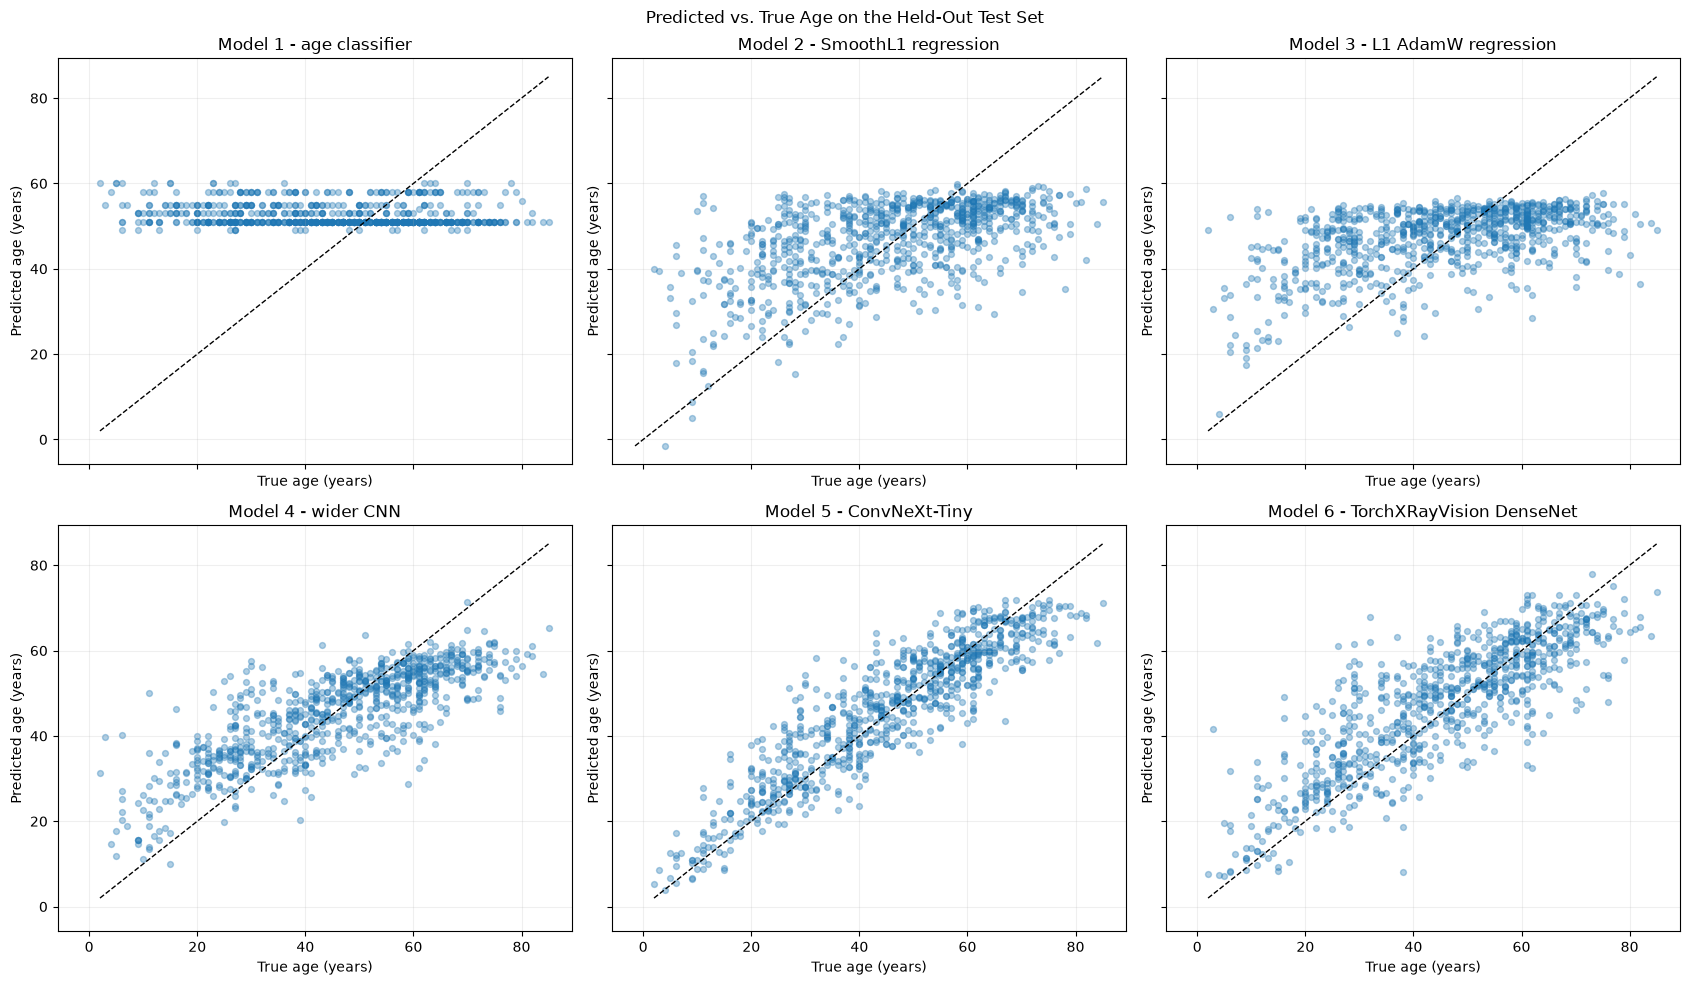

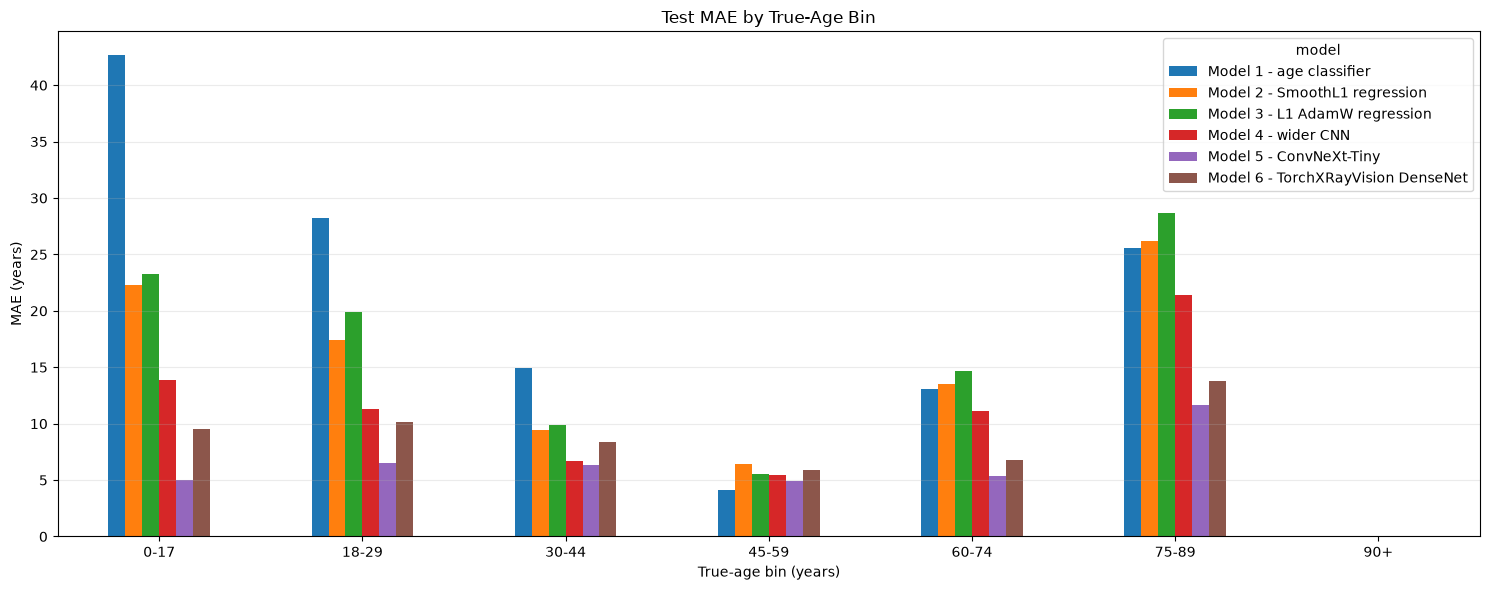

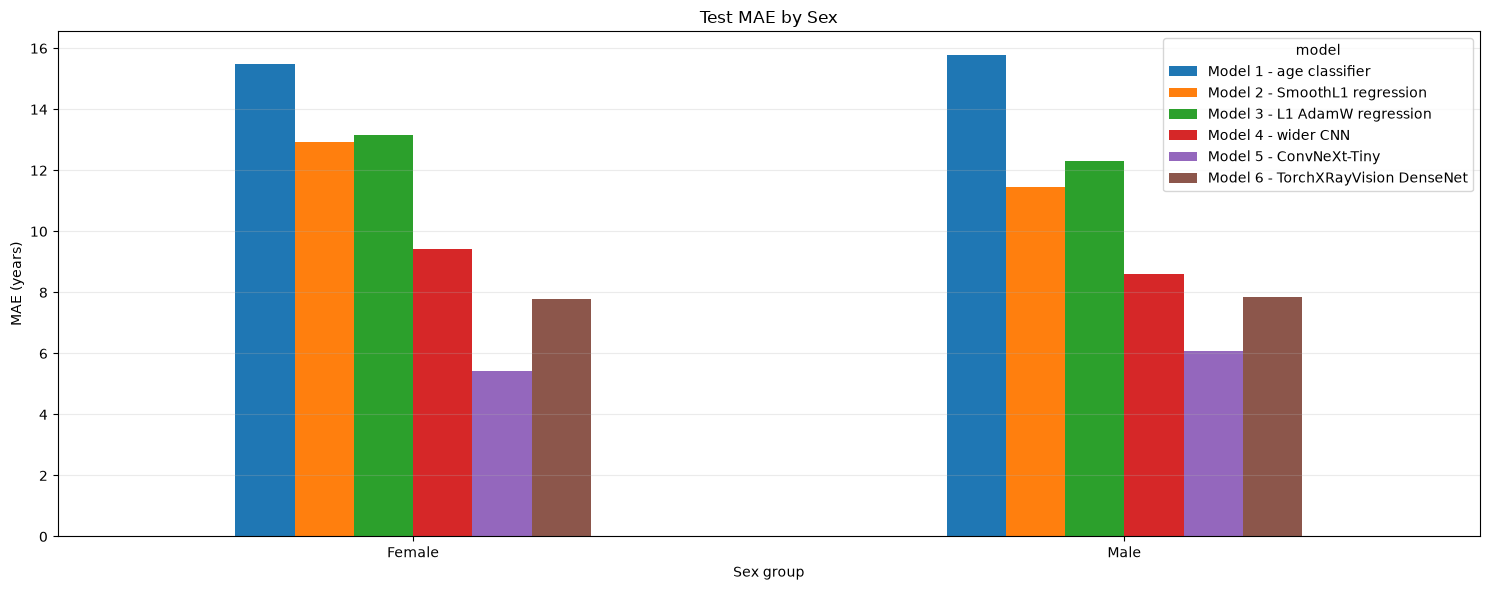

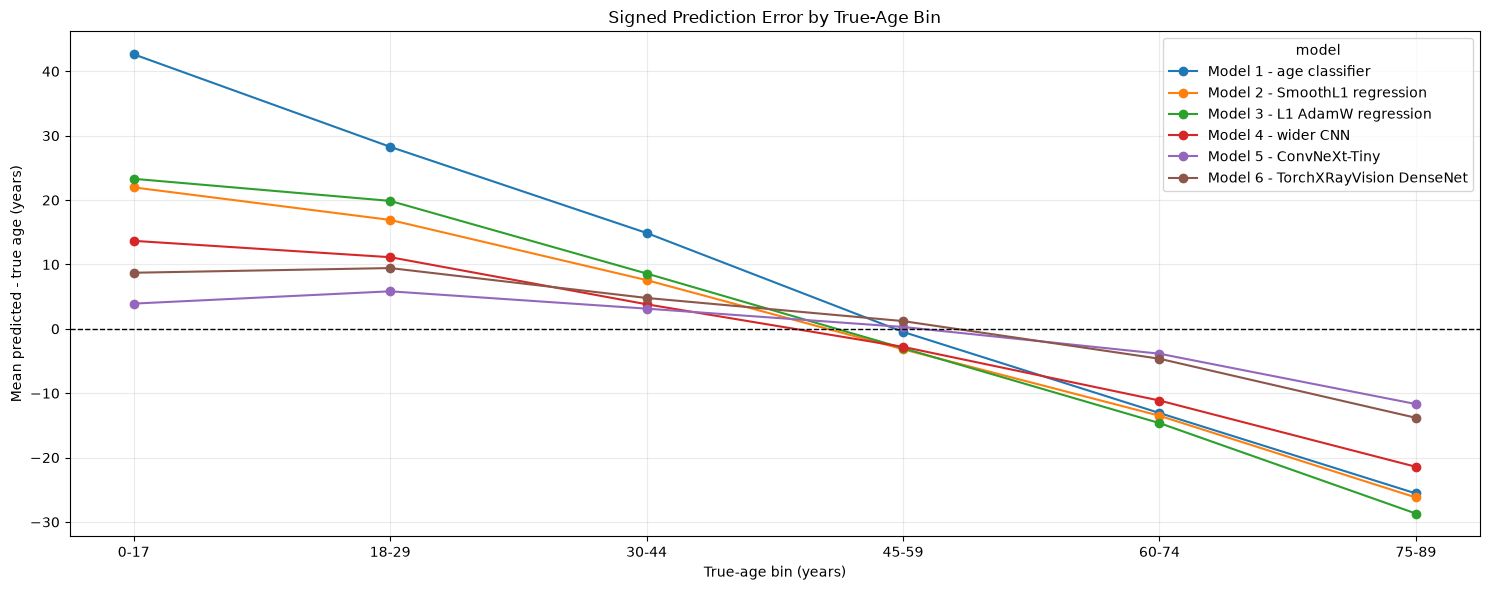

In [59]:
import matplotlib.pyplot as plt

age_bin_edges = [0, 18, 30, 45, 60, 75, 90, 121]
age_bin_labels = ["0-17", "18-29", "30-44", "45-59", "60-74", "75-89", "90+"]
model_test_predictions["age_bin"] = pd.cut(
    model_test_predictions["true_age"], bins=age_bin_edges, labels=age_bin_labels,
    right=False, include_lowest=True
)

age_error_summary = (
    model_test_predictions.groupby(["model", "age_bin"], observed=False)
    .agg(n_images=("absolute_error", "size"), mae_years=("absolute_error", "mean"),
         mean_signed_error_years=("signed_error", "mean"))
    .reset_index()
)
sex_error_summary = (
    model_test_predictions.groupby(["model", "sex_group"], observed=False)
    .agg(n_images=("absolute_error", "size"), mae_years=("absolute_error", "mean"),
         mean_signed_error_years=("signed_error", "mean"))
    .reset_index()
)
print("MAE and signed bias by true-age bin (positive bias = overprediction):")
display(age_error_summary)
print("MAE and signed bias by sex:")
display(sex_error_summary)

fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True)
for ax, (model_name, frame) in zip(axes.flat, model_test_predictions.groupby("model", sort=False)):
    ax.scatter(frame["true_age"], frame["predicted_age"], alpha=0.35, s=18)
    low = min(frame["true_age"].min(), frame["predicted_age"].min())
    high = max(frame["true_age"].max(), frame["predicted_age"].max())
    ax.plot([low, high], [low, high], "k--", linewidth=1)
    ax.set_title(model_name)
    ax.set_xlabel("True age (years)")
    ax.set_ylabel("Predicted age (years)")
    ax.grid(alpha=0.2)
fig.suptitle("Predicted vs. True Age on the Held-Out Test Set")
fig.tight_layout()
plt.show()

age_mae_pivot = age_error_summary.pivot(index="age_bin", columns="model", values="mae_years")
ax = age_mae_pivot.plot(kind="bar", figsize=(15, 6))
ax.set_title("Test MAE by True-Age Bin")
ax.set_xlabel("True-age bin (years)")
ax.set_ylabel("MAE (years)")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

sex_mae_pivot = sex_error_summary.pivot(index="sex_group", columns="model", values="mae_years")
ax = sex_mae_pivot.plot(kind="bar", figsize=(15, 6))
ax.set_title("Test MAE by Sex")
ax.set_xlabel("Sex group")
ax.set_ylabel("MAE (years)")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Signed error by age bin makes regression-to-the-mean patterns visible.
bias_pivot = age_error_summary.pivot(index="age_bin", columns="model", values="mean_signed_error_years")
ax = bias_pivot.plot(marker="o", figsize=(15, 6))
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set_title("Signed Prediction Error by True-Age Bin")
ax.set_xlabel("True-age bin (years)")
ax.set_ylabel("Mean predicted - true age (years)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Prediction shrinkage. All models pull predictions toward the middle of the age range: younger patients are overpredicted and older patients underpredicted (regression to the mean). The effect is most severe in the weakest models. Model 1 outputs nearly the same age (roughly 50 to 60 years) regardless of true age, in horizontal stripes because a classifier can only predict ages that exist as classes. With few images per age, it effectively favored a handful of common classes, consistent with its negative R². This was discussed as a potential issue which was why I abandoned using the age as a classifier and switched to regression. Models 2 and 3 show a positive but shallow trend and plateau at roughly 55 to 58 years, so patients from about 40 to 85 receive similar predictions. Model 4 tracks the diagonal much better but still underpredicts the oldest patients. Models 5 and 6 follow it most closely, though both still underpredict the oldest group.

Binned error. Signed error (predicted minus true) decreases steadily with true age and crosses zero near the 45 to 59 bin. In the youngest and oldest bins, the mean signed error is nearly equal in magnitude to the MAE, indicating that errors there are mostly systematic bias rather than random scatter. Model 1 has an MAE of about 43 years for patients under 18. Models 2 and 3 overpredict patients under 18 by more than 20 years on average and underpredict patients aged 75 to 89 by about 26 to 29 years. The pretrained models are far less biased: ConvNeXt-Tiny has an MAE of about 5 years under 18 and about 12 years for ages 75 to 89 (DenseNet: about 9.5 and 14). In the 45 to 59 bin all models perform similarly (about 4 to 6 years), including Model 1, which predicts near the middle of the range for everyone, so differences in overall MAE come mainly from the extremes of the age range.

One plausible explanation is that visual differences between younger ages (growth, skeletal maturation) are larger than the gradual changes of adult aging, making older ages harder to resolve. However, the weaker models also fail badly on young patients, and the pretrained models show that the information is present in the images, so limited capacity or representation likely plays a broader role. I did not test these explanations.

Sex-stratified MAE differed by at most about 1.5 years, with no consistent direction across models. I did not test these differences for significance.

## View Position Confounder Check

At the beginning of this project, when looking at the data I saw that there were 2 different types of xray images which turned out to be different viewing positions. To see if this is a confounding variable I will check distributions and model errors for the PA/AP views.

Test-set age distribution by View Position:


,view_position,n_images,n_patients,mean_age_years,median_age_years
0,AP,338,251,44.165680,46.0
1,PA,493,437,46.042596,47.0


Test performance stratified by View Position:


,model,view_position,n_images,mae_years,mean_signed_error_years
0,Model 1 - age classifier,AP,338,16.121302,8.263313
1,Model 1 - age classifier,PA,493,15.338742,6.527383
2,Model 2 - SmoothL1 regression,AP,338,12.298152,1.290368
3,Model 2 - SmoothL1 regression,PA,493,11.850842,1.473773
4,Model 3 - L1 AdamW regression,AP,338,13.211715,2.967178
5,Model 3 - L1 AdamW regression,PA,493,12.280959,1.229580
6,Model 4 - wider CNN,AP,338,9.472979,0.078445
7,Model 4 - wider CNN,PA,493,8.562583,-0.423850
8,Model 5 - ConvNeXt-Tiny,AP,338,6.632998,1.546167
9,Model 5 - ConvNeXt-Tiny,PA,493,5.261080,0.396162


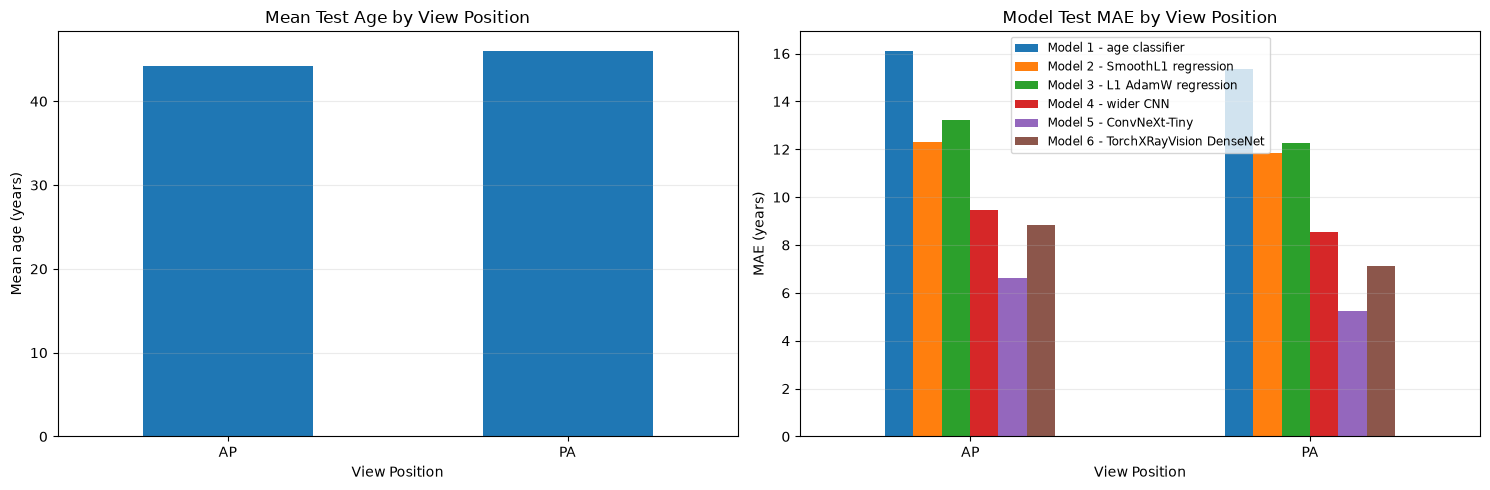

Stratification can reveal associations but does not prove a model uses View Position as a shortcut.


In [60]:
import matplotlib.pyplot as plt

# Describe how age is distributed across PA/AP views, then stratify model errors by view.
view_distribution = (
    test_metadata.assign(_view=test_metadata["View Position"].fillna("Unknown").astype(str))
    .groupby("_view")
    .agg(n_images=("Age", "size"), n_patients=("Patient ID", "nunique"),
         mean_age_years=("Age", "mean"), median_age_years=("Age", "median"))
    .reset_index()
    .rename(columns={"_view": "view_position"})
)
view_performance = (
    model_test_predictions.assign(view_position=lambda frame: frame["View Position"].fillna("Unknown").astype(str))
    .groupby(["model", "view_position"], observed=False)
    .agg(n_images=("absolute_error", "size"), mae_years=("absolute_error", "mean"),
         mean_signed_error_years=("signed_error", "mean"))
    .reset_index()
)
print("Test-set age distribution by View Position:")
display(view_distribution)
print("Test performance stratified by View Position:")
display(view_performance)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
view_distribution.set_index("view_position")["mean_age_years"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Mean Test Age by View Position")
axes[0].set_xlabel("View Position")
axes[0].set_ylabel("Mean age (years)")
view_pivot = view_performance.pivot(index="view_position", columns="model", values="mae_years")
view_pivot.plot(kind="bar", ax=axes[1])
axes[1].set_title("Model Test MAE by View Position")
axes[1].set_xlabel("View Position")
axes[1].set_ylabel("MAE (years)")
axes[1].legend(fontsize="small")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

print("Stratification can reveal associations but does not prove a model uses View Position as a shortcut.")

We can see that in general, the distributions of the means are slightly different for the 2 different views. Interestingly, even though the our models seemed to perform better for younger ages, the view position that had the smaller mean age also had the higher model test mean average error for all the models. However, the difference is quite small. Let's test to see if any of this is statistically significant.

In [63]:
import numpy as np
import pandas as pd

# Compare AP and PA test errors, keeping all images from a patient together.
view_test = model_test_predictions.copy()
view_test["view_position"] = (
    view_test["View Position"].fillna("Unknown").astype(str).str.strip().str.upper()
)
view_test = view_test.loc[view_test["view_position"].isin(["AP", "PA"])].copy()

if view_test.empty:
    raise ValueError("No AP or PA images were found in model_test_predictions.")
if view_test["Patient ID"].isna().any():
    raise ValueError("Patient ID contains missing values; patient-level bootstrap requires valid IDs.")

model_names = view_test["model"].drop_duplicates().tolist()
if not model_names:
    raise ValueError("No model predictions are available for the AP/PA comparison.")

n_bootstrap = 2000
alpha = 0.05
# Bonferroni intervals account for comparing all models in this analysis.
familywise_alpha = alpha / len(model_names)

def _sex_label(value):
    value = str(value).strip().upper()
    if value in {"F", "FEMALE"}:
        return "Female"
    if value in {"M", "MALE"}:
        return "Male"
    return "Unknown"

def _pa_ap_patient_bootstrap(frame, seed):
    frame = frame.reset_index(drop=True).copy()
    frame["sex_label"] = frame[sex_column].map(_sex_label)

    # Give each patient an integer ID for efficient cluster-level resampling.
    patient_codes, patient_ids = pd.factorize(frame["Patient ID"], sort=False)
    n_patients = len(patient_ids)
    view_code = frame["view_position"].map({"AP": 0, "PA": 1}).to_numpy()
    absolute_error = frame["absolute_error"].to_numpy(dtype=float)

    patient_view_counts = np.zeros((n_patients, 2), dtype=float)
    patient_error_sums = np.zeros((n_patients, 2), dtype=float)
    np.add.at(patient_view_counts, (patient_codes, view_code), 1)
    np.add.at(patient_error_sums, (patient_codes, view_code), absolute_error)

    patients_with_ap = np.flatnonzero(patient_view_counts[:, 0] > 0)
    patients_with_pa = np.flatnonzero(patient_view_counts[:, 1] > 0)
    if len(patients_with_ap) < 2 or len(patients_with_pa) < 2:
        raise ValueError(
            f"{frame['model'].iloc[0]} has fewer than two distinct patients "
            "in AP or PA; a patient-level CI would not be reliable."
        )

    ap_mae = patient_error_sums[:, 0].sum() / patient_view_counts[:, 0].sum()
    pa_mae = patient_error_sums[:, 1].sum() / patient_view_counts[:, 1].sum()
    difference = pa_mae - ap_mae

    # Resample patients within their AP-only, PA-only, or mixed-view group.
    patient_views = [
        tuple(np.flatnonzero(patient_view_counts[i] > 0))
        for i in range(n_patients)
    ]
    strata = {}
    for patient_code, view_membership in enumerate(patient_views):
        strata.setdefault(view_membership, []).append(patient_code)

    # Adjusted linear model: absolute error ~ view + age + age^2 + sex.
    # AP is the reference view; the PA coefficient is the adjusted PA - AP difference.
    ages = frame["true_age"].to_numpy(dtype=float)
    age_sd = ages.std()
    age_z = (ages - ages.mean()) / age_sd if age_sd > 0 else np.zeros_like(ages)
    sex_labels = frame["sex_label"].to_numpy()
    candidate_columns = [
        ("PA indicator", (frame["view_position"] == "PA").to_numpy(dtype=float)),
        ("Age", age_z),
        ("Age squared", age_z ** 2),
        ("Female", (sex_labels == "Female").astype(float)),
        ("Unknown sex", (sex_labels == "Unknown").astype(float)),
    ]

    design_columns = [np.ones(len(frame), dtype=float)]
    for _, column in candidate_columns:
        if np.ptp(column) > 0:
            design_columns.append(column)
    design = np.column_stack(design_columns)

    if np.linalg.matrix_rank(design) < design.shape[1]:
        raise ValueError(
            f"{frame['model'].iloc[0]}: age/sex/view covariates are collinear "
            "in this test sample; the adjusted comparison cannot be estimated."
        )

    # Save each patient's sufficient statistics so bootstrap iterations resample
    # patient clusters without copying the full image-level table.
    n_parameters = design.shape[1]
    patient_xtx = np.zeros((n_patients, n_parameters, n_parameters), dtype=float)
    patient_xty = np.zeros((n_patients, n_parameters), dtype=float)
    for patient_code in range(n_patients):
        rows = patient_codes == patient_code
        x_patient = design[rows]
        y_patient = absolute_error[rows]
        patient_xtx[patient_code] = x_patient.T @ x_patient
        patient_xty[patient_code] = x_patient.T @ y_patient

    observed_beta = np.linalg.lstsq(design, absolute_error, rcond=None)[0]
    adjusted_difference = observed_beta[1]

    rng = np.random.default_rng(seed)
    bootstrap_differences = []
    bootstrap_adjusted = []

    for _ in range(n_bootstrap):
        weights = np.zeros(n_patients, dtype=float)
        for stratum_patients in strata.values():
            sampled = rng.choice(
                stratum_patients,
                size=len(stratum_patients),
                replace=True,
            )
            weights += np.bincount(sampled, minlength=n_patients)

        resampled_counts = weights @ patient_view_counts
        resampled_error_sums = weights @ patient_error_sums
        if np.any(resampled_counts == 0):
            continue

        resampled_ap_mae = resampled_error_sums[0] / resampled_counts[0]
        resampled_pa_mae = resampled_error_sums[1] / resampled_counts[1]
        bootstrap_differences.append(resampled_pa_mae - resampled_ap_mae)

        xtx = np.einsum("i,ijk->jk", weights, patient_xtx)
        xty = weights @ patient_xty
        beta = np.linalg.lstsq(xtx, xty, rcond=None)[0]
        bootstrap_adjusted.append(beta[1])

    if len(bootstrap_differences) < 0.95 * n_bootstrap:
        raise RuntimeError(
            "Too many bootstrap replicates lacked AP or PA observations; "
            "the test set may have too few patients in one view group."
        )

    # Percentile confidence intervals, both ordinary and familywise-adjusted.
    ci_95 = np.percentile(
        bootstrap_differences,
        [100 * alpha / 2, 100 * (1 - alpha / 2)],
    )
    ci_familywise = np.percentile(
        bootstrap_differences,
        [100 * familywise_alpha / 2, 100 * (1 - familywise_alpha / 2)],
    )
    adjusted_ci_95 = np.percentile(
        bootstrap_adjusted,
        [100 * alpha / 2, 100 * (1 - alpha / 2)],
    )
    adjusted_ci_familywise = np.percentile(
        bootstrap_adjusted,
        [100 * familywise_alpha / 2, 100 * (1 - familywise_alpha / 2)],
    )

    return {
        "model": frame["model"].iloc[0],
        "AP_images": int(patient_view_counts[:, 0].sum()),
        "AP_patients": int(len(patients_with_ap)),
        "AP_MAE_years": float(ap_mae),
        "PA_images": int(patient_view_counts[:, 1].sum()),
        "PA_patients": int(len(patients_with_pa)),
        "PA_MAE_years": float(pa_mae),
        "PA_minus_AP_MAE_years": float(difference),
        "unadjusted_95pct_CI": tuple(ci_95),
        "unadjusted_familywise_CI": tuple(ci_familywise),
        "unadjusted_familywise_CI_excludes_zero": bool(
            ci_familywise[0] > 0 or ci_familywise[1] < 0
        ),
        "age_sex_adjusted_PA_minus_AP_years": float(adjusted_difference),
        "adjusted_95pct_CI": tuple(adjusted_ci_95),
        "adjusted_familywise_CI": tuple(adjusted_ci_familywise),
        "adjusted_familywise_CI_excludes_zero": bool(
            adjusted_ci_familywise[0] > 0 or adjusted_ci_familywise[1] < 0
        ),
        "bootstrap_replicates": len(bootstrap_differences),
    }

view_significance = pd.DataFrame(
    [
        _pa_ap_patient_bootstrap(frame, seed=2026 + model_index)
        for model_index, (_, frame) in enumerate(
            view_test.groupby("model", sort=False)
        )
    ]
)

display(view_significance)
print(
    "Positive PA-minus-AP differences indicate higher PA error. "
    "Familywise intervals adjust for the number of models compared. "
    "These are associations, not evidence that view position causes the error difference."
)

,model,AP_images,AP_patients,AP_MAE_years,PA_images,PA_patients,PA_MAE_years,PA_minus_AP_MAE_years,unadjusted_95pct_CI,unadjusted_familywise_CI,unadjusted_familywise_CI_excludes_zero,age_sex_adjusted_PA_minus_AP_years,adjusted_95pct_CI,adjusted_familywise_CI,adjusted_familywise_CI_excludes_zero,bootstrap_replicates
0,Model 1 - age classifier,338,251,16.121302,493,437,15.338742,-0.782559,"(-2.715472056399796, 1.107860243271823)","(-3.544582072078708, 1.5347266737110565)",False,0.235861,"(-0.3744818834318685, 0.8084422178210465)","(-0.565255609872876, 0.9820581992267532)",False,2000
1,Model 2 - SmoothL1 regression,338,251,12.298151,493,437,11.850843,-0.447309,"(-1.8002264446246172, 0.868195302599947)","(-2.3111517296270194, 1.3581593798484601)",False,-0.214630,"(-1.266292981761569, 0.8239236539818375)","(-1.5847196063868676, 1.128569489155708)",False,2000
2,Model 3 - L1 AdamW regression,338,251,13.211715,493,437,12.280959,-0.930756,"(-2.215172689819501, 0.33242125551486823)","(-2.6984778413167834, 0.7560833740726004)",False,-0.624471,"(-1.6209833969222822, 0.31952397221906603)","(-1.9167927502523872, 0.6145991096921669)",False,2000
3,Model 4 - wider CNN,338,251,9.472979,493,437,8.562584,-0.910395,"(-1.8588515374345964, 0.08762043056113494)","(-2.2506092881787128, 0.34021380050397104)",False,-0.861122,"(-1.732394144117116, 0.04185254510160392)","(-1.9971480790222058, 0.30990596153052263)",False,2000
4,Model 5 - ConvNeXt-Tiny,338,251,6.632997,493,437,5.261080,-1.371917,"(-2.035492086700942, -0.7104627034129091)","(-2.2904869166241046, -0.5253844540161038)",True,-1.348145,"(-2.039002261372466, -0.685317299613156)","(-2.2728278727355002, -0.5185268973909974)",True,2000
5,Model 6 - TorchXRayVision DenseNet,338,251,8.844973,493,437,7.109155,-1.735818,"(-2.7955304957145763, -0.735551236777948)","(-3.0913533689665575, -0.4668964360224589)",True,-1.620326,"(-2.6385594872566625, -0.6965870629422787)","(-2.9529006298100193, -0.4186186966137571)",True,2000


Positive PA-minus-AP differences indicate higher PA error. Familywise intervals adjust for the number of models compared. These are associations, not evidence that view position causes the error difference.


According to our analysis, view position only seems to be significant for the pretrained models. This was determined by seeing if 0 was in the range of the confidence interval of the difference MAE for the view positions. This suggests that view position may be a confounding factor. Further work can be done to further improve the models. The easiest thing to do would be to find more data to train the networks on. Dataset size was a clear limitation which affected the strength of the predictions. More experimentation with architectural structure could also be done.